# Лабораторная работа № 2
## Классификация данных и нейронные сети

**Тема:** многоклассовая классификация качества красного вина (*Wine Quality*) на основе физико-химических показателей.

**Цель:** изучить методы классификации Scikit-Learn, исследовать дисбаланс классов и SMOTE, построить многослойный перцептрон в TensorFlow/Keras и проанализировать обучение с помощью TensorBoard.

**Содержание:** исследование данных → подготовка выборок → SMOTE → четыре варианта наивного Байеса → дерево решений → LDA → SVM → kNN → поиск гиперпараметров → метрики и ROC → нейросети → TensorBoard → выводы.

> Для воспроизведения нужны **только два файла в одной папке**: этот `.ipynb` и `winequality-red.csv`. Библиотеки проверяются в первой кодовой ячейке. На первом запуске при отсутствии пакетов потребуется интернет.

## 1. Подготовка окружения

При необходимости установим недостающие библиотеки **в тот Python, который выбран ядром Jupyter**. Библиотеки, которые уже установлены, повторно скачиваться не будут. При ошибке установки проверьте выбранный Kernel в VS Code и доступ к интернету.

In [ ]:
import sys, subprocess, importlib.util

packages = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "seaborn": "seaborn", "sklearn": "scikit-learn", "imblearn": "imbalanced-learn",
    "scipy": "scipy", "tensorflow": "tensorflow", "tensorboard": "tensorboard",
}
missing = [pip_name for mod, pip_name in packages.items() if importlib.util.find_spec(mod) is None]
print("Python:", sys.version.split()[0], "|", sys.executable)
if missing:
    print("Устанавливаем:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    importlib.invalidate_caches()
    print("Установка завершена. При проблемах с импортом перезапустите Kernel и нажмите Run All.")
else:
    print("Все необходимые библиотеки уже установлены.")

**Пояснение.** `sys.executable` — интерпретатор текущего ядра. Это предотвращает ситуацию, когда пакет устанавливается в один Python, а ноутбук исполняется в другом. Если установка TensorFlow выполняется впервые и импорт не удаётся в текущей сессии, достаточно перезапустить ядро.

In [2]:
import os, warnings, logging
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve, auc, ConfusionMatrixDisplay)
from sklearn.preprocessing import label_binarize
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Фильтруем только известное информационное сообщение о GPU Windows;
# реальные ошибки TensorFlow и предупреждения о качестве обучения остаются видимыми.
class _WindowsGpuInfoFilter(logging.Filter):
    def filter(self, record):
        return "TensorFlow GPU support is not available on native Windows" not in record.getMessage()

logging.getLogger("tensorflow").addFilter(_WindowsGpuInfoFilter())
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 115, "axes.titlesize": 12})
print("Импорты выполнены. Случайное зерно:", SEED)

Импорты выполнены. Случайное зерно: 42


**Вывод.** Импортированы средства предобработки, классификации, оценки метрик, кросс-валидации и SMOTE. Фиксация `SEED` делает разбиение выборок и другие случайные операции воспроизводимыми. Она не гарантирует абсолютную идентичность результатов нейросетей на всех устройствах.

## 2. Загрузка и исследование исходных данных

Источник: [Wine Quality, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/186/wine+quality). В работе используется набор `winequality-red.csv` — физико-химические показатели красных вин и экспертная оценка качества.

Целевая переменная `quality` — **дискретный класс**. Остальные 11 столбцов — вещественные признаки. В отличие от ЛР №1 (регрессия), теперь нужно определить точную метку класса: 3, 4, 5, 6, 7 или 8.

In [3]:
DATA_FILE = Path("winequality-red.csv")
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Не найден {DATA_FILE.name}. Положите CSV рядом с notebook и откройте его папку в VS Code. "
        f"Текущая папка: {Path.cwd()}"
    )
# sep=None корректно обнаруживает разделитель и для CSV с ';', и для CSV с ','.
df = pd.read_csv(DATA_FILE, sep=None, engine="python")
assert "quality" in df.columns, "В датасете отсутствует целевая колонка quality"
print("Размер исходного набора:", df.shape)
print("Типы столбцов:")
display(df.dtypes.rename("dtype").to_frame())
display(df.head())
print("Пропусков:", int(df.isna().sum().sum()), "| Полных дубликатов:", int(df.duplicated().sum()))

Размер исходного набора: (1599, 12)
Типы столбцов:


,dtype
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Пропусков: 0 | Полных дубликатов: 240


**Интерпретация.** `shape` показывает количество строк и столбцов, `dtypes` — типы данных, `head()` — примеры наблюдений. Проверки на пропуски и дубликаты нужны до моделирования, чтобы исключить ошибочные или повторные объекты.

In [4]:
missing_by_column = df.isna().sum().rename("Пропуски")
summary = df.describe().T.round(3)
display(summary)
display(missing_by_column.to_frame())

df_clean = df.dropna(subset=["quality"]).drop_duplicates().reset_index(drop=True)
X = df_clean.drop(columns="quality").copy()
y = df_clean["quality"].astype(int).copy()
class_labels = np.sort(y.unique())
print("После удаления дубликатов:", df_clean.shape)
print("Признаков X:", X.shape[1], "| классы y:", class_labels)
print("Категориальных входных признаков нет: все X числовые, кодирование X не требуется.")

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


,Пропуски
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


После удаления дубликатов: (1359, 12)
Признаков X: 11 | классы y: [3 4 5 6 7 8]
Категориальных входных признаков нет: все X числовые, кодирование X не требуется.


**Вывод.** Целевой класс кодировать не нужно: метки `quality` уже числовые. При этом пропущенные значения во входных X, если они появятся, будут заполняться медианой **внутри обучающего Pipeline**, чтобы статистика тестовых данных не попадала в обучение. Удаление полных дубликатов выполняется до разбиения, чтобы один и тот же объект не попал и в train, и в test.

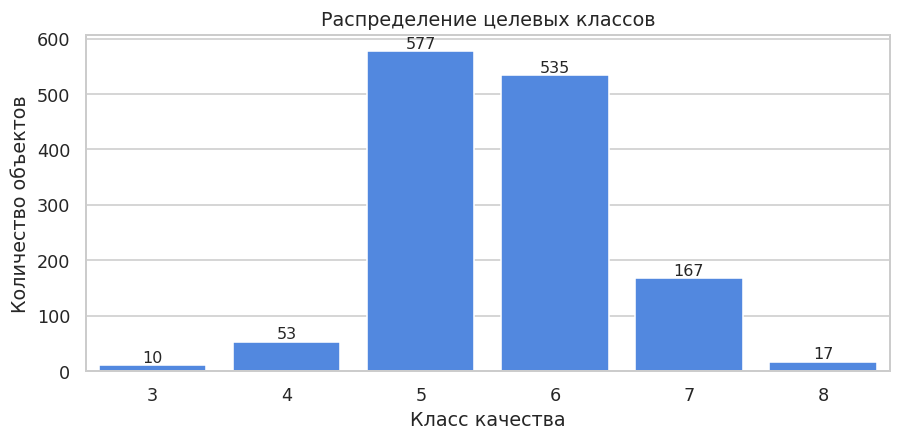

,Количество
quality,
3,10
4,53
5,577
6,535
7,167
8,17


Самый редкий класс: 3 (10 объектов); самый многочисленный: 5 (577).


In [5]:
counts = y.value_counts().reindex(class_labels, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=counts.index.astype(str), y=counts.values, color="#3b82f6", ax=ax)
for i, v in enumerate(counts): ax.text(i, v + 5, str(v), ha="center", fontsize=10)
ax.set(xlabel="Класс качества", ylabel="Количество объектов", title="Распределение целевых классов")
plt.tight_layout(); plt.show()
display(counts.rename("Количество").to_frame())
print(f"Самый редкий класс: {counts.idxmin()} ({counts.min()} объектов); самый многочисленный: {counts.idxmax()} ({counts.max()}).")

**Вывод.** Распределение классов неравномерно: оценки 5 и 6 преобладают, а 3 и 8 встречаются редко. При таком дисбалансе большая Accuracy может скрывать низкую полноту редких классов. Поэтому для выбора гиперпараметров используется **F1 macro**, а для обучения дополнительно исследуется SMOTE.

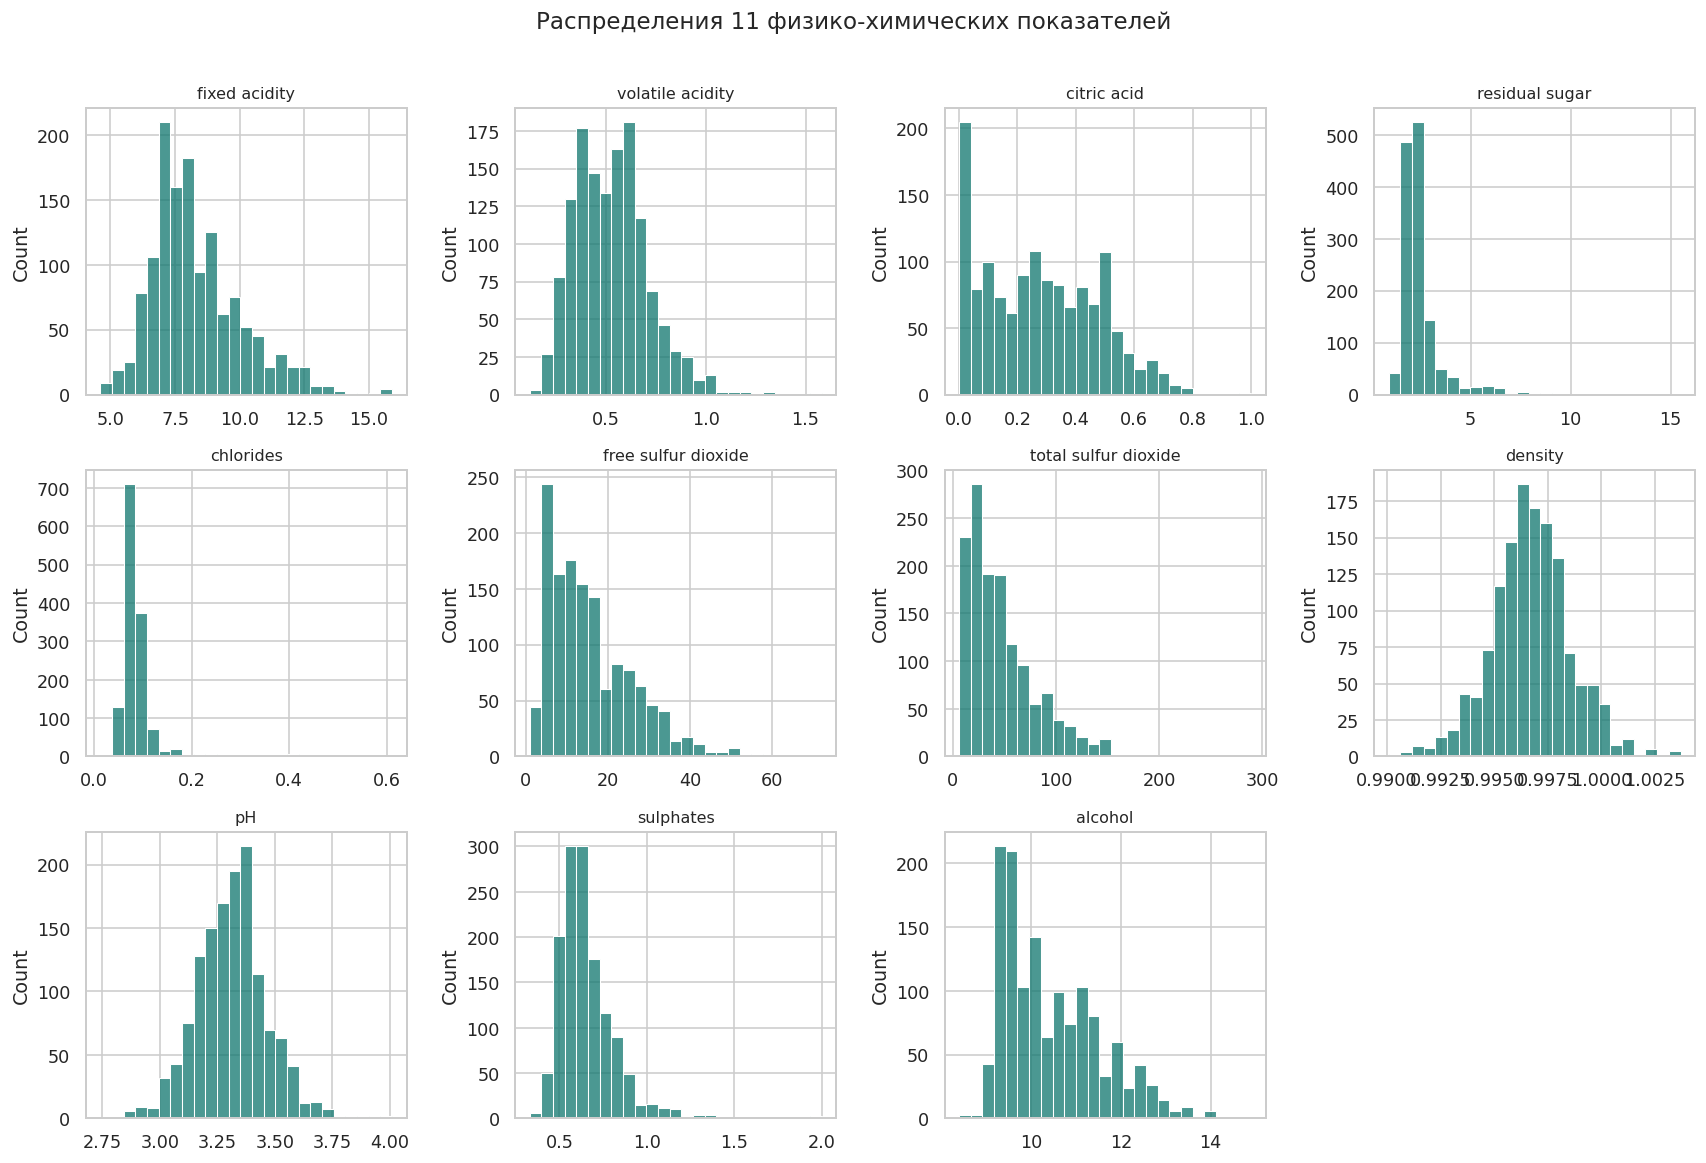

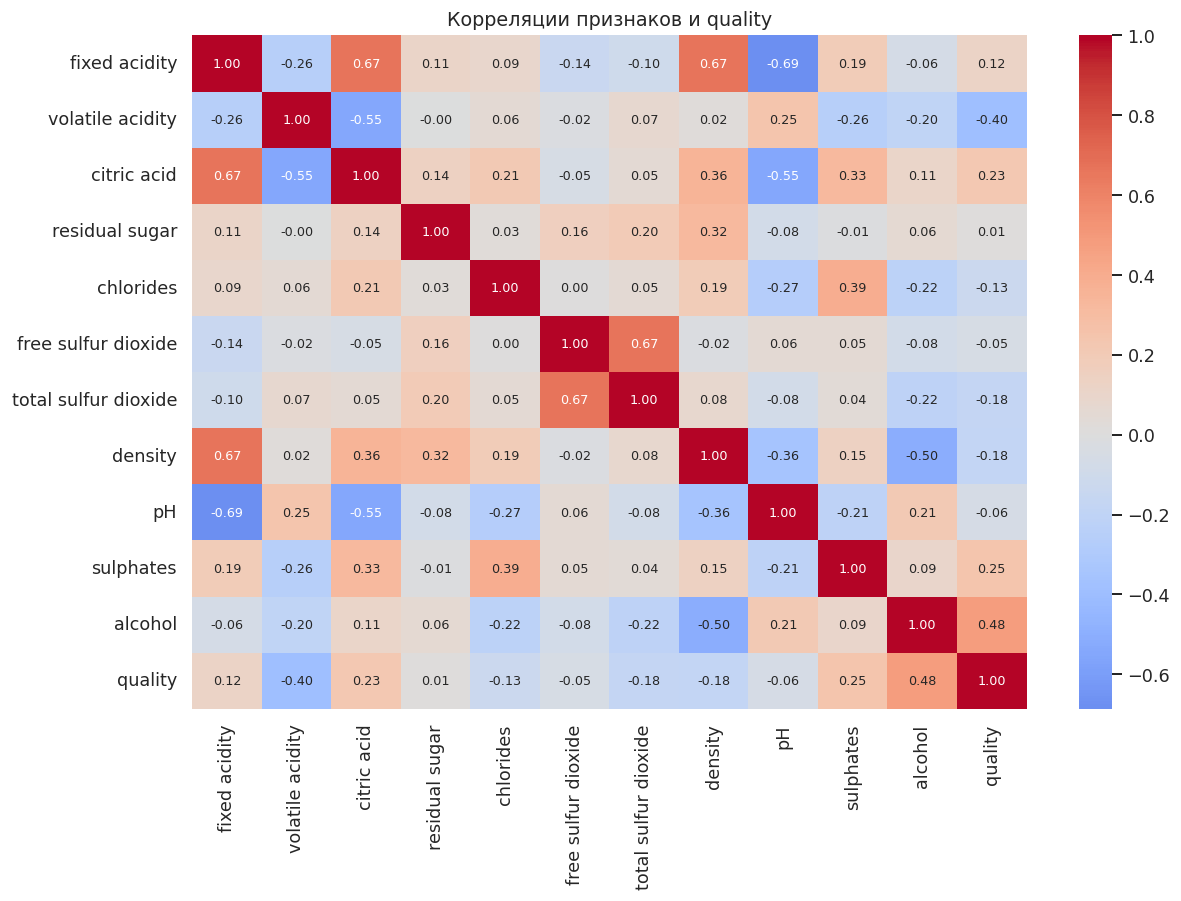

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for i, name in enumerate(X.columns):
    sns.histplot(X[name], bins=25, ax=axes.flat[i], color="#0f766e", edgecolor="white")
    axes.flat[i].set_title(name, fontsize=10)
    axes.flat[i].set_xlabel("")
axes.flat[-1].axis("off")
plt.suptitle("Распределения 11 физико-химических показателей", y=1.01)
plt.tight_layout(); plt.show()

plt.figure(figsize=(11, 8))
sns.heatmap(df_clean.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            annot_kws={"size": 8})
plt.title("Корреляции признаков и quality")
plt.tight_layout(); plt.show()

**Пояснение.** Гистограммы помогают заметить асимметрию и разные масштабы признаков. Корреляционная матрица показывает линейные связи; она не доказывает причинную связь. Для SVM, LDA и kNN масштабирование важно, поскольку признаки измеряются в разных единицах.

## 3. Разделение данных и балансировка SMOTE

Сначала делим очищенные данные на тренировочную (80%) и тестовую (20%) выборки. Используем `stratify=y`, чтобы приблизительно сохранить доли классов. **Тестовая выборка не изменяется SMOTE и не участвует в подборе параметров.**

Train: (1087, 11) | Test: (272, 11)


,Train,Test
quality,,
3,8,2
4,42,11
5,461,116
6,428,107
7,134,33
8,14,3


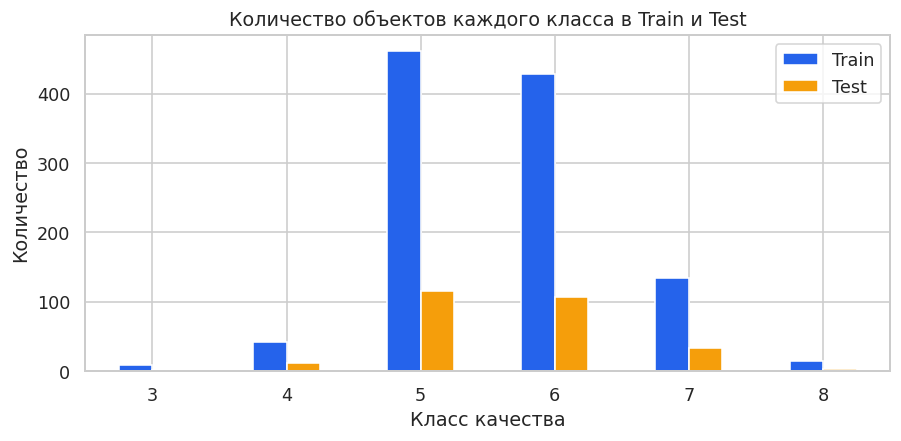

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
train_test_counts = pd.DataFrame({
    "Train": y_train.value_counts().reindex(class_labels, fill_value=0),
    "Test": y_test.value_counts().reindex(class_labels, fill_value=0),
})
display(train_test_counts)
train_test_counts.plot(kind="bar", figsize=(8, 4), color=["#2563eb", "#f59e0b"])
plt.title("Количество объектов каждого класса в Train и Test")
plt.xlabel("Класс качества"); plt.ylabel("Количество"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

**Вывод.** Фиксация `random_state` делает разделение воспроизводимым. Поскольку класс 3 очень редок, особенно важно сохранить его представителей в обеих выборках. Итоговую оценку моделей выполняем на естественном, несбалансированном тестовом распределении.

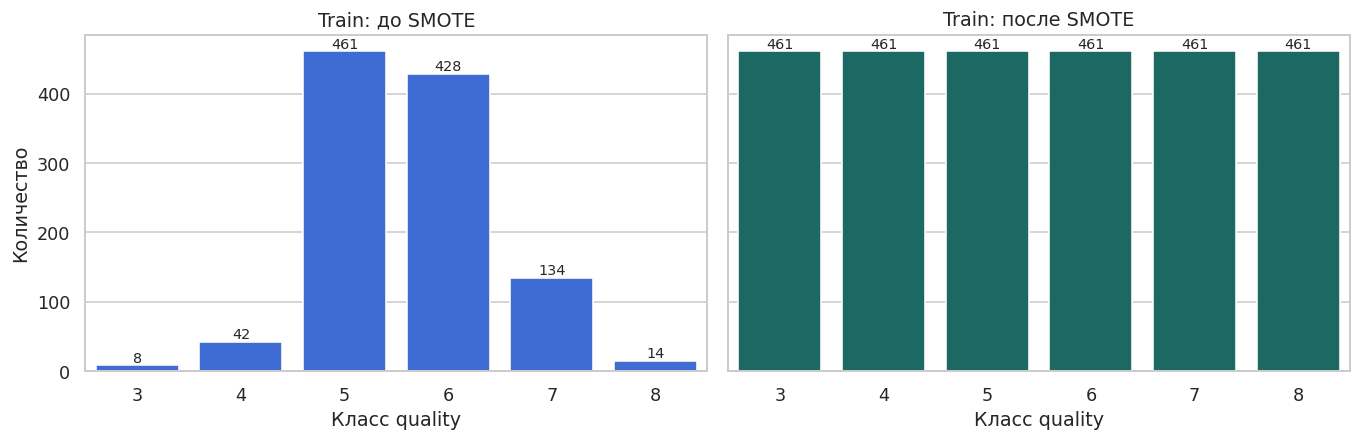

,До SMOTE,После SMOTE
quality,,
3,8,461
4,42,461
5,461,461
6,428,461
7,134,461
8,14,461


Test остался без изменений: {3: 2, 4: 11, 5: 116, 6: 107, 7: 33, 8: 3}


In [8]:
# Демонстрация SMOTE: сначала fit_transform только на Train, затем балансировка только Train.
scaler_demo = StandardScaler()
X_train_scaled_demo = scaler_demo.fit_transform(X_train)
smote_demo = SMOTE(random_state=SEED, k_neighbors=3)
X_demo_bal, y_demo_bal = smote_demo.fit_resample(X_train_scaled_demo, y_train)
before = y_train.value_counts().reindex(class_labels, fill_value=0)
after = pd.Series(y_demo_bal).value_counts().reindex(class_labels, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, series, title, color in [
    (axes[0], before, "Train: до SMOTE", "#2563eb"),
    (axes[1], after, "Train: после SMOTE", "#0f766e")
]:
    sns.barplot(x=series.index.astype(str), y=series.values, color=color, ax=ax)
    for i, v in enumerate(series): ax.text(i, v + 5, str(v), ha="center", fontsize=9)
    ax.set(title=title, xlabel="Класс quality", ylabel="Количество")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"До SMOTE": before, "После SMOTE": after}))
print("Test остался без изменений:", y_test.value_counts().sort_index().to_dict())

**Как работает SMOTE.** Алгоритм синтезирует новые объекты редкого класса между близкими объектами **этого же класса**: `x_new = x_i + λ(x_j − x_i)`, где `λ ∈ [0,1]`. Он не добавляет новых реальных измерений. Мы используем три ближайших соседа из-за небольшого количества образцов классов 3 и 8.

**Важное различие:** демонстрация выше нужна только для графика. Для настоящего обучения SMOTE будет находиться **внутри Pipeline и кросс-валидации**, а не применяться один раз к общей обучающей выборке перед CV. Это предотвращает утечку синтетических примеров из тренировочного fold в валидационный.

## 4. Классификаторы Scikit-Learn

Исследуем те же пять семейств, что в работе-образце одногруппника: четыре разновидности наивного Байеса, Decision Tree, LDA, SVM и kNN. Для каждого сравним обычное обучение и обучение с SMOTE.

**Порядок работы:** заполнение пропусков → масштабирование (где нужно) → SMOTE (при включении) → классификатор. Подбор параметров проводится на тренировочных данных по пятифолдовой стратифицированной CV.

In [9]:
from sklearn.base import clone

# GaussianNB и модели на расстояниях получают стандартизованные данные.
# Multinomial/Complement/Bernoulli получают неотрицательные признаки через MinMaxScaler.
models_config = {
    "GaussianNB": {
        "model": GaussianNB(), "scale": "standard",
        "grid": {"model__var_smoothing": [1e-9, 1e-7, 1e-5]},
    },
    "MultinomialNB": {
        "model": MultinomialNB(), "scale": "minmax",
        "grid": {"model__alpha": [0.1, 1.0, 5.0]},
    },
    "ComplementNB": {
        "model": ComplementNB(), "scale": "minmax",
        "grid": {"model__alpha": [0.1, 1.0, 5.0]},
    },
    "BernoulliNB": {
        "model": BernoulliNB(), "scale": "minmax",
        "grid": {"model__alpha": [0.1, 1.0], "model__binarize": [0.3, 0.6]},
    },
    "Decision Tree": {
        "model": DecisionTreeClassifier(random_state=SEED), "scale": "none",
        "grid": {"model__criterion": ["gini", "entropy"],
                 "model__max_depth": [4, 8], "model__min_samples_leaf": [2, 6]},
    },
    "LDA": {
        "model": LinearDiscriminantAnalysis(solver="lsqr"), "scale": "standard",
        "grid": {"model__shrinkage": [None, "auto", 0.2]},
    },
    "SVM": {
        "model": SVC(kernel="rbf", random_state=SEED), "scale": "standard",
        "grid": {"estimator__model__C": [1.0, 5.0], "estimator__model__gamma": ["scale", 0.1]},
    },
    "kNN": {
        "model": KNeighborsClassifier(), "scale": "standard",
        "grid": {"model__n_neighbors": [5, 11], "model__weights": ["uniform", "distance"]},
    },
}

def make_pipeline(name, use_smote=False):
    cfg = models_config[name]
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if cfg["scale"] == "standard":
        steps.append(("scaler", StandardScaler()))
    elif cfg["scale"] == "minmax":
        steps.append(("scaler", MinMaxScaler()))
    if use_smote:
        steps.append(("smote", SMOTE(random_state=SEED, k_neighbors=3)))
    steps.append(("model", clone(cfg["model"])))
    base_pipeline = ImbPipeline(steps)
    if name == "SVM":
        # Scikit-Learn 1.9+: SVC(probability=True) устарел.
        # Калибруем оценки SVC отдельной стратифицированной CV.
        # Важно: вся предобработка и SMOTE внутри estimator, поэтому
        # ни объекты калибровки, ни тест не участвуют в синтезе соседей.
        return CalibratedClassifierCV(
            estimator=base_pipeline,
            method="sigmoid",
            cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
            ensemble=False,
        )
    return base_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("Определено моделей:", len(models_config), "| CV folds:", cv.n_splits)
print("Пример Pipeline:", make_pipeline("SVM", use_smote=True))

Определено моделей: 8 | CV folds: 5
Пример Pipeline: CalibratedClassifierCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
                       ensemble=False,
                       estimator=Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler()),
                                                 ('smote',
                                                  SMOTE(k_neighbors=3,
                                                        random_state=42)),
                                                 ('model',
                                                  SVC(random_state=42))]))


**Почему разные преобразования?** GaussianNB подходит для непрерывных признаков. MultinomialNB и ComplementNB требуют неотрицательных значений, поэтому используется MinMaxScaler; это адаптация метода к физико-химическим показателям, а не предположение о том, что измерения стали счётчиками. BernoulliNB дополнительно переводит признаки в бинарную форму по порогу. Дерево решений не зависит от масштаба так же, как методы на расстояниях.

In [10]:
# Сравнение честное: подбор только на Train, SMOTE — внутри каждого обучающего fold.
searches = {}
records = []
for name, cfg in models_config.items():
    for use_smote in [False, True]:
        mode = "SMOTE" if use_smote else "Без SMOTE"
        gs = GridSearchCV(
            estimator=make_pipeline(name, use_smote),
            param_grid=cfg["grid"],
            scoring="f1_macro",
            cv=cv,
            n_jobs=1,
            refit=True,
            return_train_score=True,
        )
        gs.fit(X_train, y_train)
        searches[(name, mode)] = gs
        records.append({
            "Метод": name, "Режим": mode,
            "CV F1 macro": gs.best_score_,
            "Лучшие параметры": str(gs.best_params_),
        })
        print(f"{name:15s} | {mode:9s} | CV F1 macro = {gs.best_score_:.4f}")
cv_results = pd.DataFrame(records)
display(cv_results.round(4))

GaussianNB      | Без SMOTE | CV F1 macro = 0.3468


GaussianNB      | SMOTE     | CV F1 macro = 0.2200
MultinomialNB   | Без SMOTE | CV F1 macro = 0.1872


MultinomialNB   | SMOTE     | CV F1 macro = 0.2331
ComplementNB    | Без SMOTE | CV F1 macro = 0.2381


ComplementNB    | SMOTE     | CV F1 macro = 0.1403
BernoulliNB     | Без SMOTE | CV F1 macro = 0.2662


BernoulliNB     | SMOTE     | CV F1 macro = 0.2086


Decision Tree   | Без SMOTE | CV F1 macro = 0.2760


... (3 outputs left out)

SVM             | SMOTE     | CV F1 macro = 0.2832


kNN             | Без SMOTE | CV F1 macro = 0.2704


kNN             | SMOTE     | CV F1 macro = 0.3153


,Метод,Режим,CV F1 macro,Лучшие параметры
0,GaussianNB,Без SMOTE,0.3468,{'model__var_smoothing': 1e-09}
1,GaussianNB,SMOTE,0.2200,{'model__var_smoothing': 1e-09}
2,MultinomialNB,Без SMOTE,0.1872,{'model__alpha': 5.0}
3,MultinomialNB,SMOTE,0.2331,{'model__alpha': 0.1}
4,ComplementNB,Без SMOTE,0.2381,{'model__alpha': 1.0}
5,ComplementNB,SMOTE,0.1403,{'model__alpha': 0.1}
6,BernoulliNB,Без SMOTE,0.2662,"{'model__alpha': 0.1, 'model__binarize': 0.3}"
7,BernoulliNB,SMOTE,0.2086,"{'model__alpha': 1.0, 'model__binarize': 0.3}"
8,Decision Tree,Без SMOTE,0.2760,"{'model__criterion': 'entropy', 'model__max_de..."
9,Decision Tree,SMOTE,0.2714,"{'model__criterion': 'gini', 'model__max_depth..."


**Пояснение.** `GridSearchCV` перебирает заданные сетки гиперпараметров, использует `StratifiedKFold(5)` и выбирает настройки с максимальным средним F1 macro. После выбора `best_estimator_` обучен на всех тренировочных данных. Результаты CV — основание для выбора конфигурации; **тестовые метрики в подбор не входят**.

In [11]:
# ВЫВОД МЕТРИК: в качестве вероятностей используем predict_proba, а не готовые метки.
def evaluate_model(model, X_eval, y_eval):
    pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)
    labels_order = model.classes_   # порядок столбцов вероятностей у конкретного классификатора
    result = {
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision macro": precision_score(y_eval, pred, average="macro", zero_division=0),
        "Recall macro": recall_score(y_eval, pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y_eval, pred, average="macro", zero_division=0),
        "ROC AUC macro OvR": roc_auc_score(
            y_eval, proba, labels=labels_order, multi_class="ovr", average="macro"
        ),
    }
    return result, pred, proba

# Одинаковая тестовая выборка для всех моделей; сравнение режимов SMOTE/без SMOTE.
test_records = []
predictions = {}
probabilities = {}
for (name, mode), search in searches.items():
    metrics, pred, proba = evaluate_model(search.best_estimator_, X_test, y_test)
    predictions[(name, mode)] = pred
    probabilities[(name, mode)] = proba
    test_records.append({"Метод": name, "Режим": mode, **metrics})
test_results = pd.DataFrame(test_records)
display(test_results.sort_values("F1 macro", ascending=False).round(4))

,Метод,Режим,Accuracy,Precision macro,Recall macro,F1 macro,ROC AUC macro OvR
0,GaussianNB,Без SMOTE,0.5441,0.2922,0.3013,0.2948,0.6893
12,SVM,Без SMOTE,0.6140,0.2925,0.2955,0.2923,0.7813
10,LDA,Без SMOTE,0.5846,0.2857,0.2827,0.2816,0.7792
14,kNN,Без SMOTE,0.5735,0.2739,0.2790,0.2757,0.7054
13,SVM,SMOTE,0.5735,0.2616,0.2857,0.2716,0.7279
15,kNN,SMOTE,0.4375,0.2781,0.3162,0.2650,0.6322
8,Decision Tree,Без SMOTE,0.5221,0.2468,0.2574,0.2518,0.5686
6,BernoulliNB,Без SMOTE,0.5184,0.2359,0.2624,0.2461,0.6743
11,LDA,SMOTE,0.4044,0.2737,0.2503,0.2404,0.7203
4,ComplementNB,Без SMOTE,0.5147,0.2316,0.2485,0.2288,0.7151


**Вывод.** Для несбалансированной многоклассовой задачи `F1 macro` уделяет равное внимание всем шести классам, тогда как Accuracy сильнее отражает качество многочисленных классов. `ROC AUC macro OvR` вычисляется по **вероятностям** каждого класса по схеме One-vs-Rest.

**Важно для защиты:** итоговый выбор модели по результатам многочисленных просмотров Test может вносить оптимизм. Для основного заключения о лучшей конфигурации ориентируемся на CV, а Test используем для независимой оценки выбранного решения.

## 4.1. Наивный Байес

Наивный Байес применяет теорему Байеса и условную независимость признаков. Для непрерывных химических измерений наиболее естественный вариант — GaussianNB.

In [12]:
# Единый стиль матрицы ошибок — как в работе-образце:
# фиолетовая тепловая карта, значения в клетках, ось X — Факт, ось Y — Прогноз.
# В sklearn confusion_matrix строки — истинные метки, столбцы — предсказания.
# Поэтому при выбранных подписях осей используем транспонирование .T.
def plot_confusion_like_sample(y_true, y_pred, title, labels=class_labels):
    matrix = confusion_matrix(y_true, y_pred, labels=labels).T
    fig, ax = plt.subplots(figsize=(6.5, 5.4))
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Purples", ax=ax,
        xticklabels=[str(c) for c in labels],
        yticklabels=[str(c) for c in labels],
        linewidths=0.35, linecolor="#ede9f2",
        cbar=True, square=True, annot_kws={"size": 10}
    )
    ax.set_title("Матрица ошибок " + str(title), fontsize=13, pad=12)
    ax.set_xlabel("Факт", fontsize=11)
    ax.set_ylabel("Прогноз", fontsize=11)
    ax.tick_params(axis="both", labelrotation=0)
    plt.tight_layout()
    plt.show()
    return matrix

# Выбор режима выполняется только по кросс-валидации на Train, не по Test.
def show_model_matrix(model_name):
    rows = cv_results[cv_results["Метод"] == model_name]
    best = rows.sort_values("CV F1 macro", ascending=False).iloc[0]
    mode = best["Режим"]
    print(f"{model_name}: режим {mode}; CV F1 macro = {best['CV F1 macro']:.4f}")
    return plot_confusion_like_sample(
        y_test, predictions[(model_name, mode)], f"{model_name} ({mode})"
    )

print("Формат: X — истинный класс; Y — предсказанный класс; диагональ — правильные ответы.")

Формат: X — истинный класс; Y — предсказанный класс; диагональ — правильные ответы.


,Метод,Режим,Accuracy,Precision macro,Recall macro,F1 macro,ROC AUC macro OvR
0,GaussianNB,Без SMOTE,0.5441,0.2922,0.3013,0.2948,0.6893
6,BernoulliNB,Без SMOTE,0.5184,0.2359,0.2624,0.2461,0.6743
4,ComplementNB,Без SMOTE,0.5147,0.2316,0.2485,0.2288,0.7151
3,MultinomialNB,SMOTE,0.3493,0.2891,0.3021,0.2193,0.7003
7,BernoulliNB,SMOTE,0.3640,0.2530,0.2924,0.2188,0.6692
2,MultinomialNB,Без SMOTE,0.5331,0.1734,0.2135,0.1868,0.7087
1,GaussianNB,SMOTE,0.2794,0.2417,0.2250,0.1784,0.6020
5,ComplementNB,SMOTE,0.2500,0.1502,0.3095,0.1398,0.7026


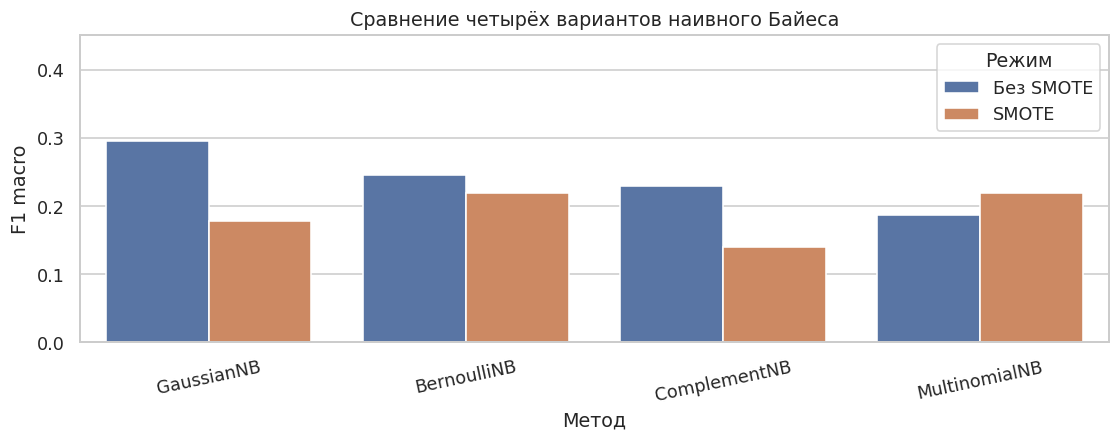

Лучший Байес по CV: {'Метод': 'GaussianNB', 'Режим': 'Без SMOTE', 'CV F1 macro': 0.34679193215235565}


In [13]:
nb_names = ["GaussianNB", "MultinomialNB", "ComplementNB", "BernoulliNB"]
nb_table = test_results[test_results["Метод"].isin(nb_names)].sort_values("F1 macro", ascending=False)
display(nb_table.round(4))
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=nb_table, x="Метод", y="F1 macro", hue="Режим", ax=ax)
ax.set(title="Сравнение четырёх вариантов наивного Байеса", ylim=(0, max(0.45, float(nb_table["F1 macro"].max())*1.2)))
plt.xticks(rotation=12); plt.tight_layout(); plt.show()
print("Лучший Байес по CV:", cv_results[cv_results["Метод"].isin(nb_names)].sort_values("CV F1 macro", ascending=False).iloc[0][["Метод", "Режим", "CV F1 macro"]].to_dict())

### Матрицы ошибок четырёх вариантов наивного Байеса

Как в работе-образце, для каждого классификатора приведена фиолетовая матрица ошибок с числом объектов в каждой клетке. Для отображения выбран режим (с SMOTE или без него) с наилучшим **CV F1 macro на обучающих данных**, чтобы не выбирать модель по тестовой выборке.

GaussianNB: режим Без SMOTE; CV F1 macro = 0.3468


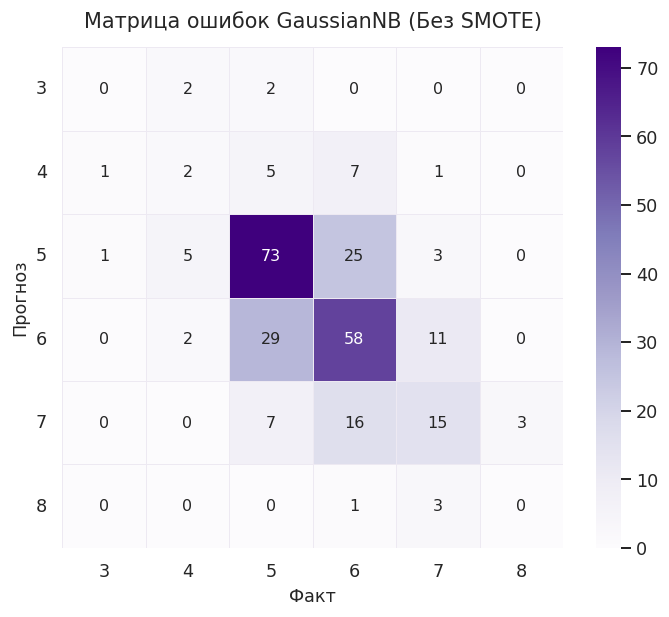

MultinomialNB: режим SMOTE; CV F1 macro = 0.2331


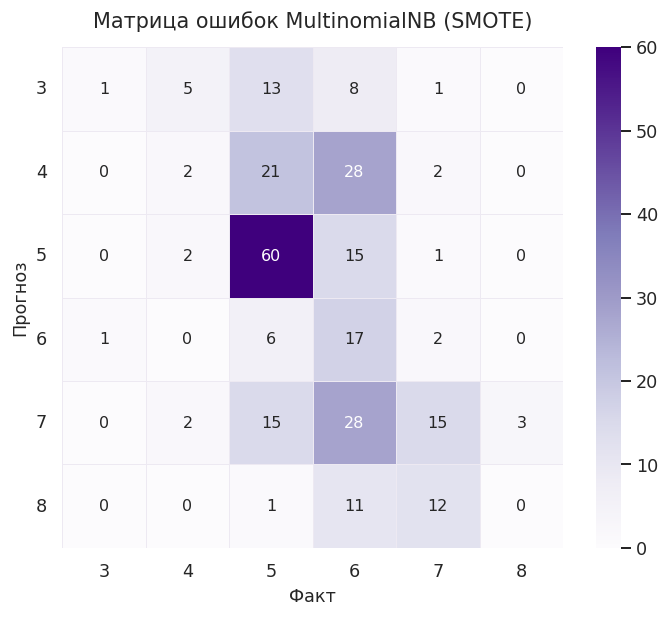

ComplementNB: режим Без SMOTE; CV F1 macro = 0.2381


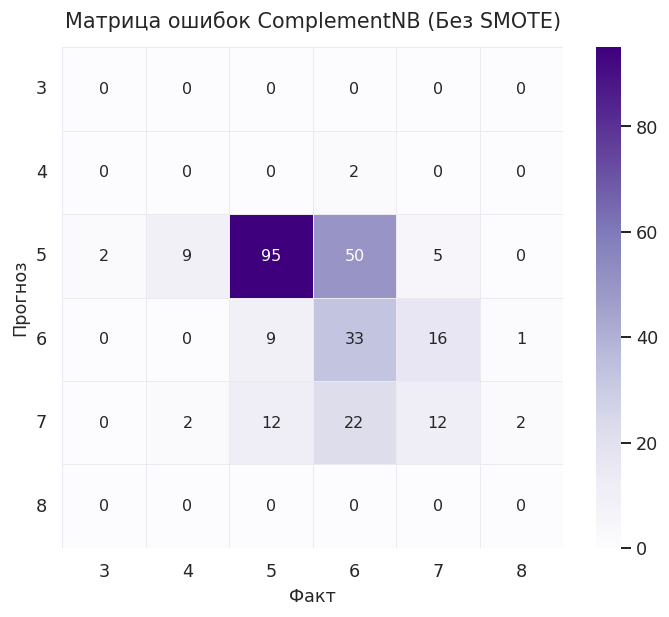

BernoulliNB: режим Без SMOTE; CV F1 macro = 0.2662


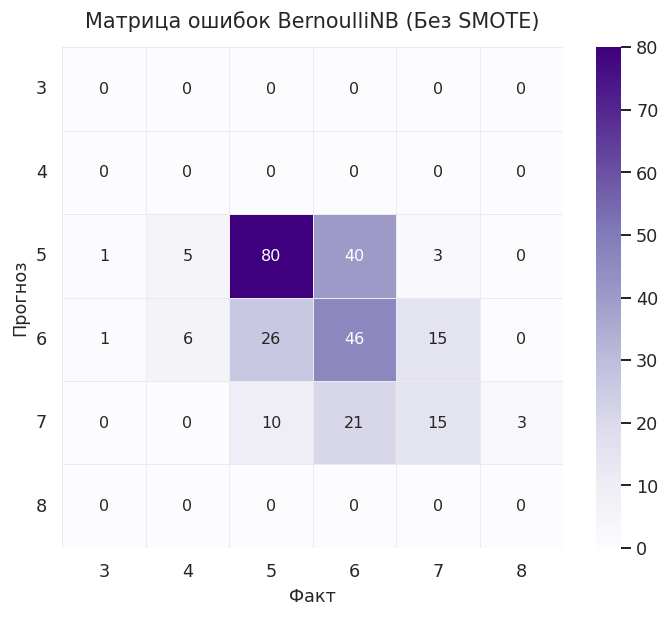

In [14]:
for nb_name in nb_names:
    show_model_matrix(nb_name)

**Интерпретация.** На диагонали расположены верные предсказания. Вне диагонали — ошибки между оценками вина. Классы 3 и 8 встречаются редко, поэтому по ним может наблюдаться небольшое число верных прогнозов. Это не делает матрицу ошибочной, а отражает дисбаланс и сложность задачи.

**Вывод.** Сравниваем GaussianNB, MultinomialNB, ComplementNB и BernoulliNB не только по общей доле верных ответов, но и по F1 macro. Качество Multinomial/Bernoulli на непрерывных признаках оценивается как экспериментальная адаптация; хорошие результаты не делают их исходные распределительные предпосылки полностью верными.

## 4.2. Дерево решений

Дерево выбирает последовательные разбиения по критерию неоднородности (`gini`/`entropy`). Его глубина и размер листа ограничивают сложность.

,Метод,Режим,Accuracy,Precision macro,Recall macro,F1 macro,ROC AUC macro OvR
8,Decision Tree,Без SMOTE,0.5221,0.2468,0.2574,0.2518,0.5686
9,Decision Tree,SMOTE,0.3640,0.2350,0.2170,0.2120,0.5659


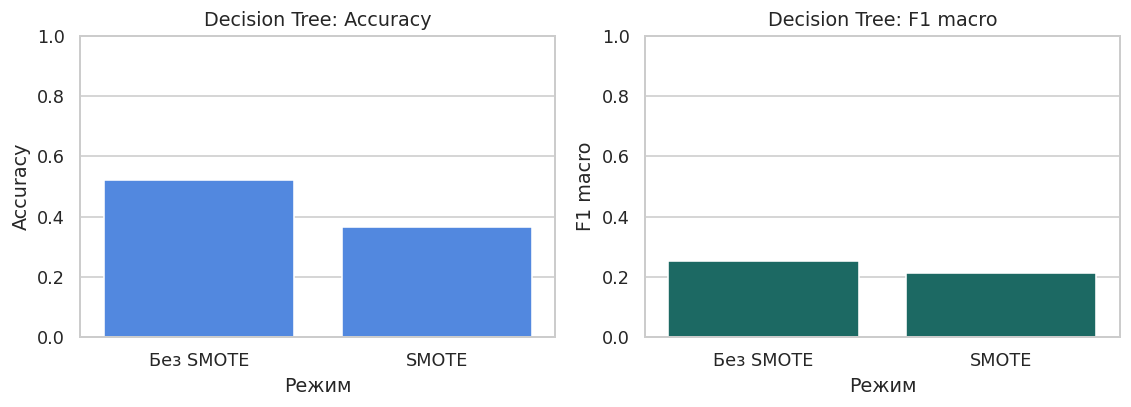

Лучшие параметры без SMOTE: {'model__criterion': 'entropy', 'model__max_depth': 8, 'model__min_samples_leaf': 2}
Лучшие параметры c SMOTE: {'model__criterion': 'gini', 'model__max_depth': 8, 'model__min_samples_leaf': 6}


In [15]:
name = 'Decision Tree'
subset = test_results[test_results["Метод"] == name].copy()
display(subset.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
sns.barplot(data=subset, x="Режим", y="Accuracy", color="#3b82f6", ax=axes[0])
sns.barplot(data=subset, x="Режим", y="F1 macro", color="#0f766e", ax=axes[1])
axes[0].set_ylim(0, 1); axes[1].set_ylim(0, 1)
axes[0].set_title(f"{name}: Accuracy"); axes[1].set_title(f"{name}: F1 macro")
plt.tight_layout(); plt.show()
print("Лучшие параметры без SMOTE:", searches[(name, "Без SMOTE")].best_params_)
print("Лучшие параметры c SMOTE:", searches[(name, "SMOTE")].best_params_)

Decision Tree: режим Без SMOTE; CV F1 macro = 0.2760


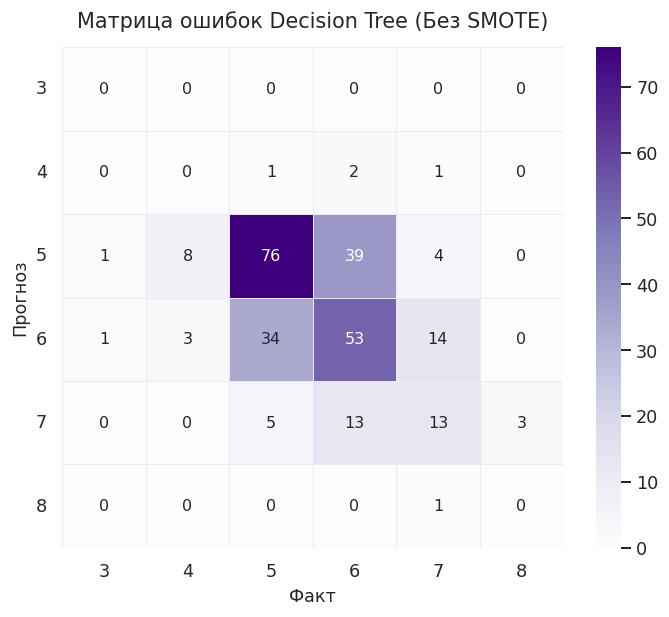

array([[ 0,  0,  0,  0,  0,  0],
       [ 0,  0,  1,  2,  1,  0],
       [ 1,  8, 76, 39,  4,  0],
       [ 1,  3, 34, 53, 14,  0],
       [ 0,  0,  5, 13, 13,  3],
       [ 0,  0,  0,  0,  1,  0]])

In [16]:
show_model_matrix("Decision Tree")

**Интерпретация.** Сравнение на одинаковом Test демонстрирует влияние балансировки на две метрики. Если F1 macro растёт, а Accuracy уменьшается, модель может уделять больше внимания малочисленным классам ценой ошибок на распространённых. Это не универсальная закономерность — вывод делается по полученным числам.

Глубина дерева: 8 | Листьев: 122


,Важность
alcohol,0.242296
volatile acidity,0.155450
sulphates,0.152163
total sulfur dioxide,0.087833
citric acid,0.064661
residual sugar,0.064210
free sulfur dioxide,0.062054
pH,0.053525
chlorides,0.046107
fixed acidity,0.044979


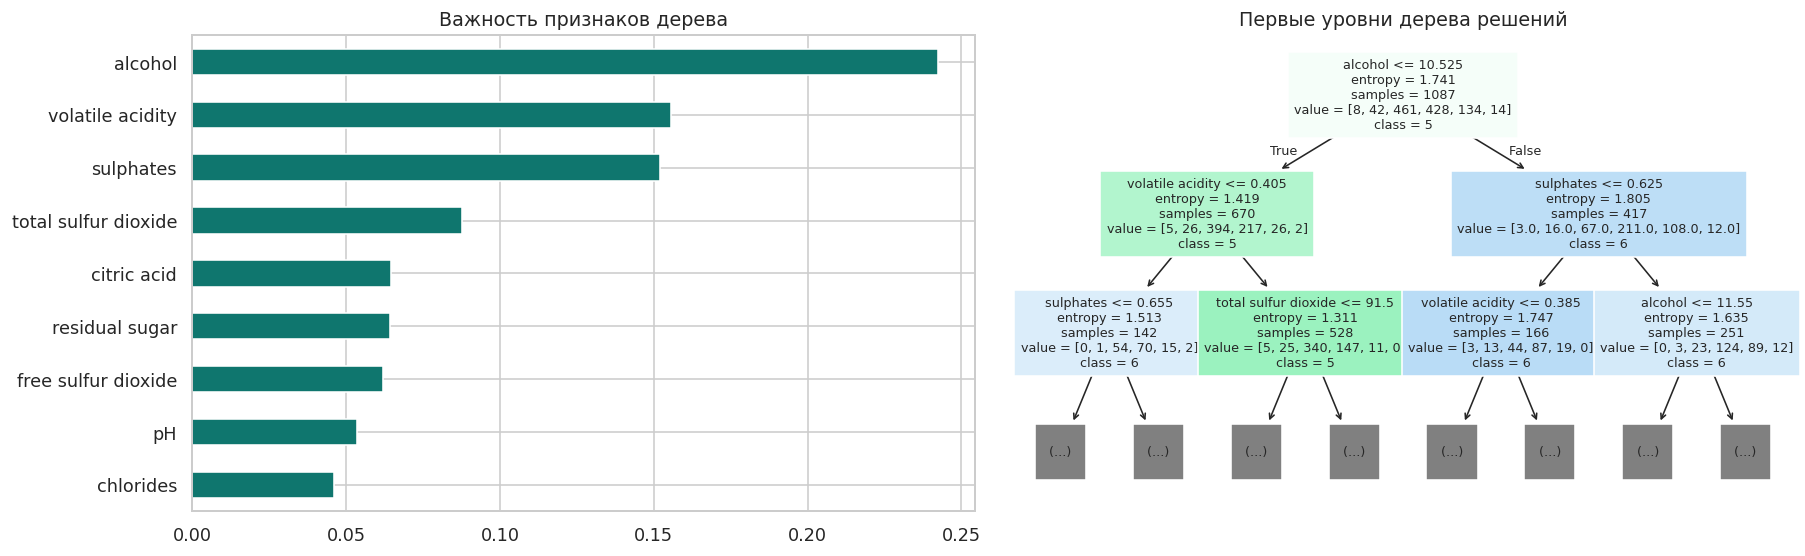

In [17]:
# Характеристики дерева из выигравшего по CV режима.
tree_mode = cv_results[cv_results["Метод"] == "Decision Tree"].sort_values("CV F1 macro", ascending=False).iloc[0]["Режим"]
tree_pipe = searches[("Decision Tree", tree_mode)].best_estimator_
tree = tree_pipe.named_steps["model"]
print("Глубина дерева:", tree.get_depth(), "| Листьев:", tree.get_n_leaves())
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
display(imp.rename("Важность").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
imp.head(9).sort_values().plot(kind="barh", ax=axes[0], color="#0f766e")
axes[0].set_title("Важность признаков дерева")
plot_tree(tree, max_depth=2, filled=True, feature_names=X.columns,
          class_names=[str(c) for c in tree.classes_], fontsize=8, ax=axes[1])
axes[1].set_title("Первые уровни дерева решений")
plt.tight_layout(); plt.show()

**Вывод.** `get_depth()` и `get_n_leaves()` показывают сложность построенного дерева; `feature_importances_` отражает относительный вклад признаков в уменьшение критерия неоднородности. Важность не доказывает причинное влияние переменной на качество вина.

## 4.3. Линейный дискриминантный анализ

LDA предполагает близкую к нормальной структуру распределений признаков в классах и общую ковариационную матрицу.

,Метод,Режим,Accuracy,Precision macro,Recall macro,F1 macro,ROC AUC macro OvR
10,LDA,Без SMOTE,0.5846,0.2857,0.2827,0.2816,0.7792
11,LDA,SMOTE,0.4044,0.2737,0.2503,0.2404,0.7203


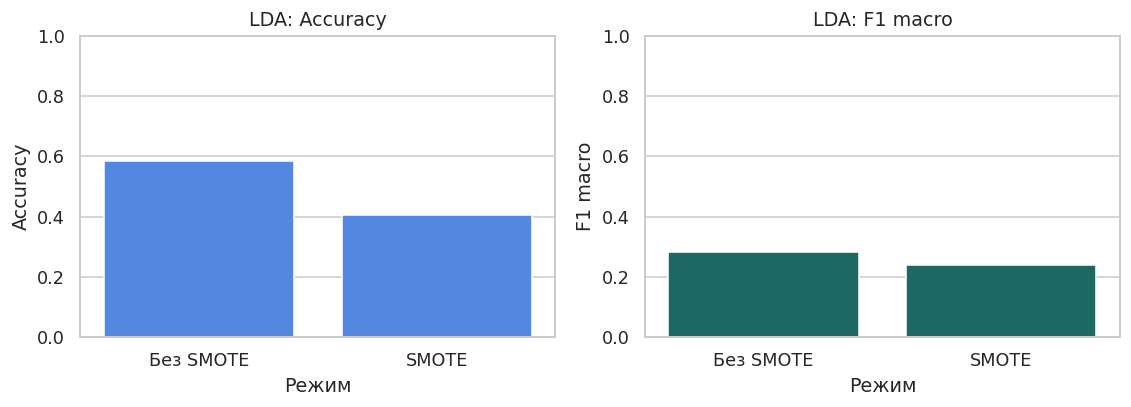

Лучшие параметры без SMOTE: {'model__shrinkage': 0.2}
Лучшие параметры c SMOTE: {'model__shrinkage': None}


In [18]:
name = 'LDA'
subset = test_results[test_results["Метод"] == name].copy()
display(subset.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
sns.barplot(data=subset, x="Режим", y="Accuracy", color="#3b82f6", ax=axes[0])
sns.barplot(data=subset, x="Режим", y="F1 macro", color="#0f766e", ax=axes[1])
axes[0].set_ylim(0, 1); axes[1].set_ylim(0, 1)
axes[0].set_title(f"{name}: Accuracy"); axes[1].set_title(f"{name}: F1 macro")
plt.tight_layout(); plt.show()
print("Лучшие параметры без SMOTE:", searches[(name, "Без SMOTE")].best_params_)
print("Лучшие параметры c SMOTE:", searches[(name, "SMOTE")].best_params_)

LDA: режим Без SMOTE; CV F1 macro = 0.3217


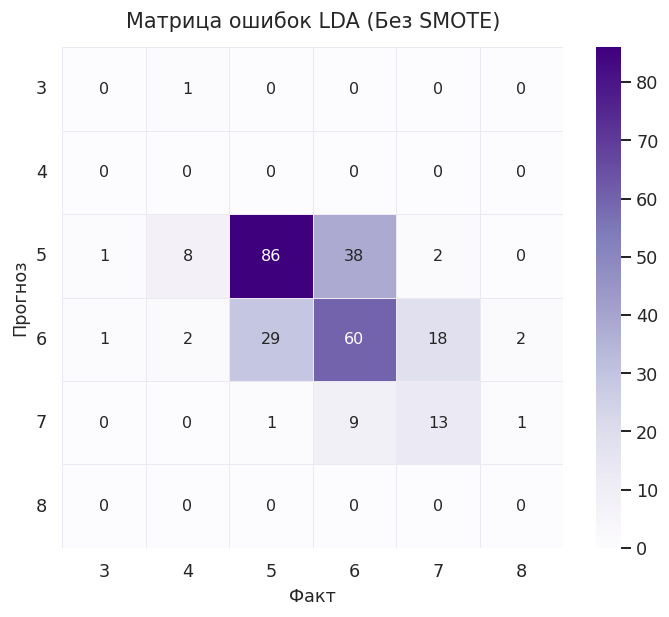

array([[ 0,  1,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0],
       [ 1,  8, 86, 38,  2,  0],
       [ 1,  2, 29, 60, 18,  2],
       [ 0,  0,  1,  9, 13,  1],
       [ 0,  0,  0,  0,  0,  0]])

In [19]:
show_model_matrix("LDA")

**Интерпретация.** Сравнение на одинаковом Test демонстрирует влияние балансировки на две метрики. Если F1 macro растёт, а Accuracy уменьшается, модель может уделять больше внимания малочисленным классам ценой ошибок на распространённых. Это не универсальная закономерность — вывод делается по полученным числам.

## 4.4. Метод опорных векторов

SVM с RBF-ядром строит нелинейную разделяющую границу. C и gamma контролируют её сложность.

В используемой версии Scikit-Learn `SVC(probability=True)` устарел. Чтобы получать вероятности для ROC-AUC без этого предупреждения, применяется `CalibratedClassifierCV` с `ensemble=False`.

Калибровка выполняется **только на обучающей выборке**: внутри неё масштабирование и SMOTE входят в отдельный Pipeline, что предотвращает утечку при внутренних разбиениях. Поэтому параметры SVM в `GridSearchCV` имеют префикс `estimator__model__`.


,Метод,Режим,Accuracy,Precision macro,Recall macro,F1 macro,ROC AUC macro OvR
12,SVM,Без SMOTE,0.6140,0.2925,0.2955,0.2923,0.7813
13,SVM,SMOTE,0.5735,0.2616,0.2857,0.2716,0.7279


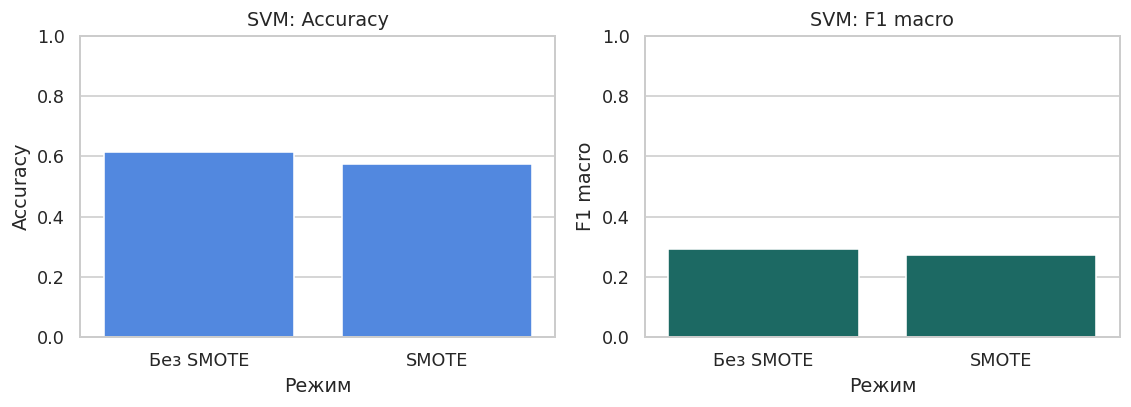

Лучшие параметры без SMOTE: {'estimator__model__C': 5.0, 'estimator__model__gamma': 0.1}
Лучшие параметры c SMOTE: {'estimator__model__C': 5.0, 'estimator__model__gamma': 0.1}


In [20]:
name = 'SVM'
subset = test_results[test_results["Метод"] == name].copy()
display(subset.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
sns.barplot(data=subset, x="Режим", y="Accuracy", color="#3b82f6", ax=axes[0])
sns.barplot(data=subset, x="Режим", y="F1 macro", color="#0f766e", ax=axes[1])
axes[0].set_ylim(0, 1); axes[1].set_ylim(0, 1)
axes[0].set_title(f"{name}: Accuracy"); axes[1].set_title(f"{name}: F1 macro")
plt.tight_layout(); plt.show()
print("Лучшие параметры без SMOTE:", searches[(name, "Без SMOTE")].best_params_)
print("Лучшие параметры c SMOTE:", searches[(name, "SMOTE")].best_params_)

SVM: режим Без SMOTE; CV F1 macro = 0.2853


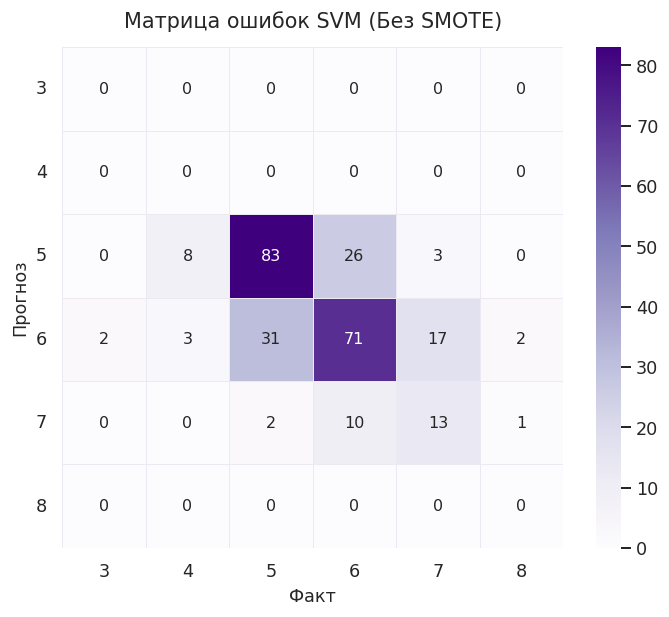

array([[ 0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0],
       [ 0,  8, 83, 26,  3,  0],
       [ 2,  3, 31, 71, 17,  2],
       [ 0,  0,  2, 10, 13,  1],
       [ 0,  0,  0,  0,  0,  0]])

In [21]:
show_model_matrix("SVM")

**Интерпретация.** Сравнение на одинаковом Test демонстрирует влияние балансировки на две метрики. Если F1 macro растёт, а Accuracy уменьшается, модель может уделять больше внимания малочисленным классам ценой ошибок на распространённых. Это не универсальная закономерность — вывод делается по полученным числам.

## 4.5. Метод ближайших соседей

kNN классифицирует по ближайшим объектам; на результат влияют количество соседей и взвешивание по расстоянию.

,Метод,Режим,Accuracy,Precision macro,Recall macro,F1 macro,ROC AUC macro OvR
14,kNN,Без SMOTE,0.5735,0.2739,0.2790,0.2757,0.7054
15,kNN,SMOTE,0.4375,0.2781,0.3162,0.2650,0.6322


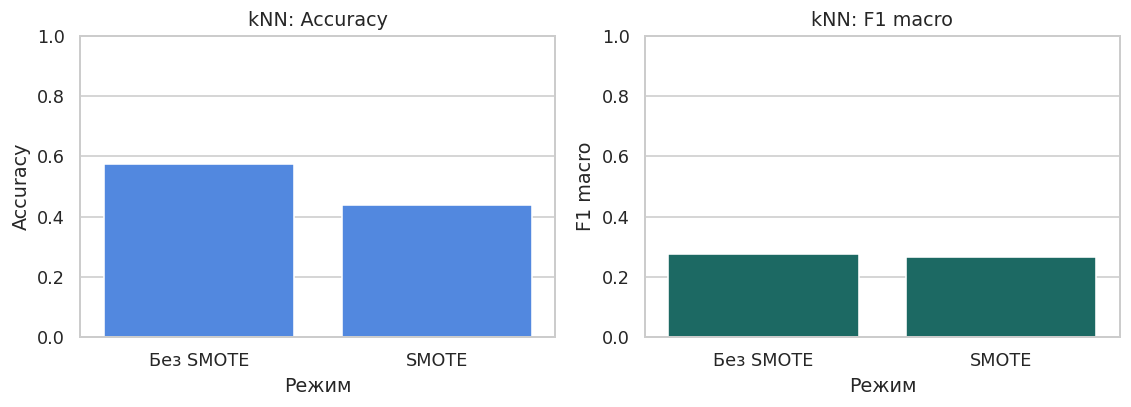

Лучшие параметры без SMOTE: {'model__n_neighbors': 11, 'model__weights': 'distance'}
Лучшие параметры c SMOTE: {'model__n_neighbors': 5, 'model__weights': 'distance'}


In [22]:
name = 'kNN'
subset = test_results[test_results["Метод"] == name].copy()
display(subset.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
sns.barplot(data=subset, x="Режим", y="Accuracy", color="#3b82f6", ax=axes[0])
sns.barplot(data=subset, x="Режим", y="F1 macro", color="#0f766e", ax=axes[1])
axes[0].set_ylim(0, 1); axes[1].set_ylim(0, 1)
axes[0].set_title(f"{name}: Accuracy"); axes[1].set_title(f"{name}: F1 macro")
plt.tight_layout(); plt.show()
print("Лучшие параметры без SMOTE:", searches[(name, "Без SMOTE")].best_params_)
print("Лучшие параметры c SMOTE:", searches[(name, "SMOTE")].best_params_)

kNN: режим SMOTE; CV F1 macro = 0.3153


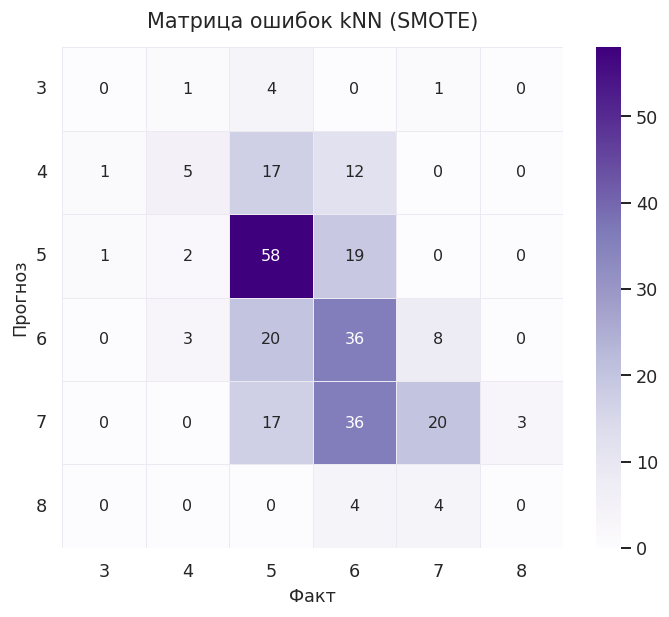

array([[ 0,  1,  4,  0,  1,  0],
       [ 1,  5, 17, 12,  0,  0],
       [ 1,  2, 58, 19,  0,  0],
       [ 0,  3, 20, 36,  8,  0],
       [ 0,  0, 17, 36, 20,  3],
       [ 0,  0,  0,  4,  4,  0]])

In [23]:
show_model_matrix("kNN")

**Интерпретация.** Сравнение на одинаковом Test демонстрирует влияние балансировки на две метрики. Если F1 macro растёт, а Accuracy уменьшается, модель может уделять больше внимания малочисленным классам ценой ошибок на распространённых. Это не универсальная закономерность — вывод делается по полученным числам.

## 5. Матрица ошибок лучшего классического классификатора и ROC-кривые

Для всех восьми классификаторов матрицы ошибок уже приведены в соответствующих разделах — **как в работе одногруппника**. Здесь дополнительно показываем выбранный по CV лучший классический вариант и строим многоклассовые ROC-кривые One-vs-Rest.

Лучший по CV: ('GaussianNB', 'Без SMOTE')
Параметры: {'model__var_smoothing': 1e-09}
Оценки на независимом Test:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.12      0.18      0.15        11
           5       0.68      0.63      0.65       116
           6       0.58      0.54      0.56       107
           7       0.37      0.45      0.41        33
           8       0.00      0.00      0.00         3

    accuracy                           0.54       272
   macro avg       0.29      0.30      0.29       272
weighted avg       0.57      0.54      0.55       272



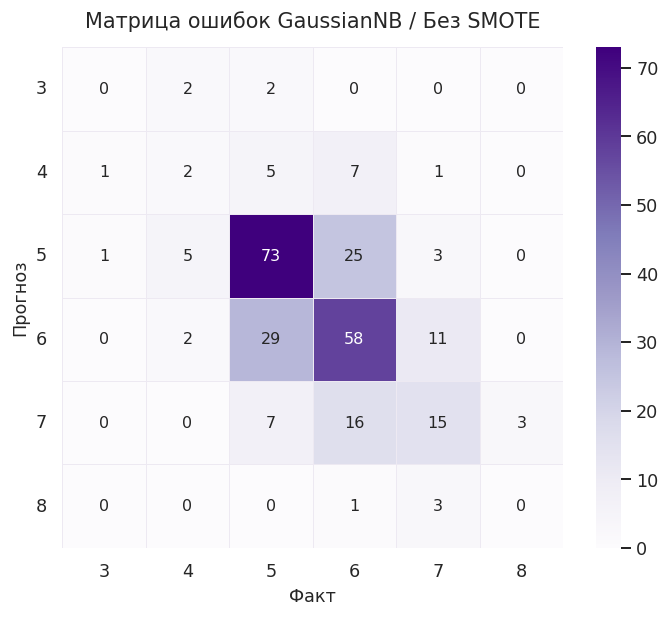

In [24]:
selected_cv_row = cv_results.sort_values("CV F1 macro", ascending=False).iloc[0]
selected_key = (selected_cv_row["Метод"], selected_cv_row["Режим"])
selected = searches[selected_key].best_estimator_
print("Лучший по CV:", selected_key)
print("Параметры:", searches[selected_key].best_params_)
print("Оценки на независимом Test:")
print(classification_report(y_test, predictions[selected_key], labels=class_labels,
                            target_names=[str(x) for x in class_labels], zero_division=0))
best_classic_matrix = plot_confusion_like_sample(
    y_test, predictions[selected_key],
    " / ".join(selected_key),
)


**Как читать матрицу ошибок.** Как и в принятой работе-образце, **по горизонтали (X) — фактическая оценка**, **по вертикали (Y) — предсказанная оценка**. Например, клетка при X = 5, Y = 6 показывает, сколько вин с реальной оценкой 5 модель ошибочно отнесла к классу 6. Правильные ответы стоят на диагонали. Чтобы сохранить такой порядок осей, стандартная матрица из `sklearn` отображается с транспонированием `.T`. Цветовая палитра `Purples`, подписи и числа в клетках соответствуют образцу одногруппника.

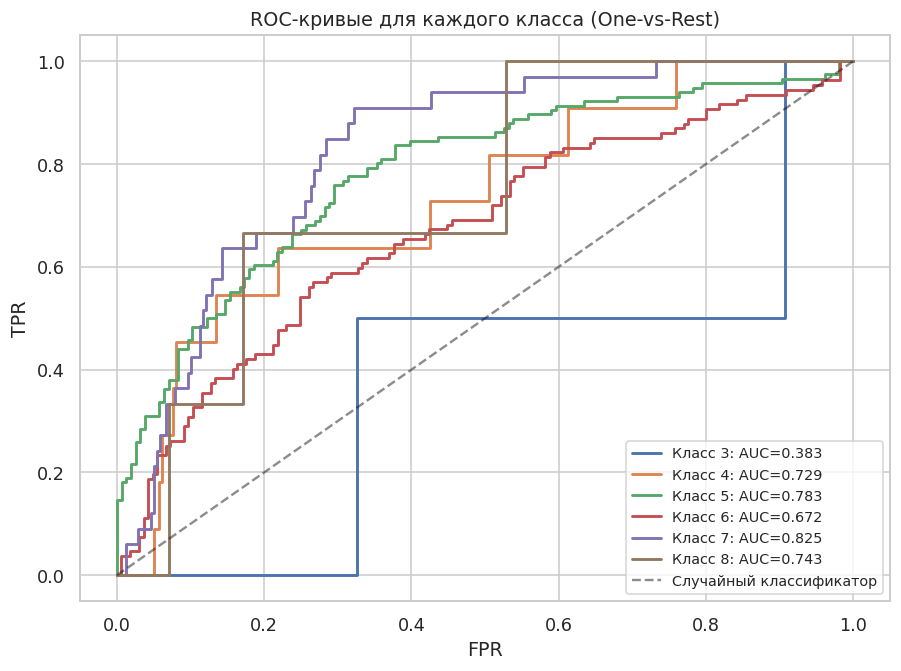

,Класс,AUC (OvR)
0,3,0.3833
1,4,0.7290
2,5,0.7830
3,6,0.6718
4,7,0.8250
5,8,0.7435


Общая ROC AUC macro OvR: 0.6893


In [25]:
proba_best = probabilities[selected_key]
classes_best = selected.classes_
Y_test_bin = label_binarize(y_test, classes=classes_best)
fig, ax = plt.subplots(figsize=(8, 6))
roc_details = []
for j, cls in enumerate(classes_best):
    fpr, tpr, _ = roc_curve(Y_test_bin[:, j], proba_best[:, j])
    per_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, lw=1.8, label=f"Класс {cls}: AUC={per_auc:.3f}")
    roc_details.append({"Класс": int(cls), "AUC (OvR)": per_auc})
ax.plot([0,1], [0,1], "k--", alpha=.5, label="Случайный классификатор")
ax.set(xlabel="FPR", ylabel="TPR", title="ROC-кривые для каждого класса (One-vs-Rest)")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()
display(pd.DataFrame(roc_details).round(4))
print("Общая ROC AUC macro OvR:", round(roc_auc_score(
    y_test, proba_best, labels=classes_best, average="macro", multi_class="ovr"), 4))

**Вывод.** ROC строится по числовым оценкам модели — вероятностям `predict_proba`, а не по готовым меткам `predict`. Для каждого класса он временно считается положительным, остальные — отрицательными. Чем ближе AUC к 1, тем лучше модель ранжирует объекты данного класса относительно остальных; на редких классах значения менее устойчивы.

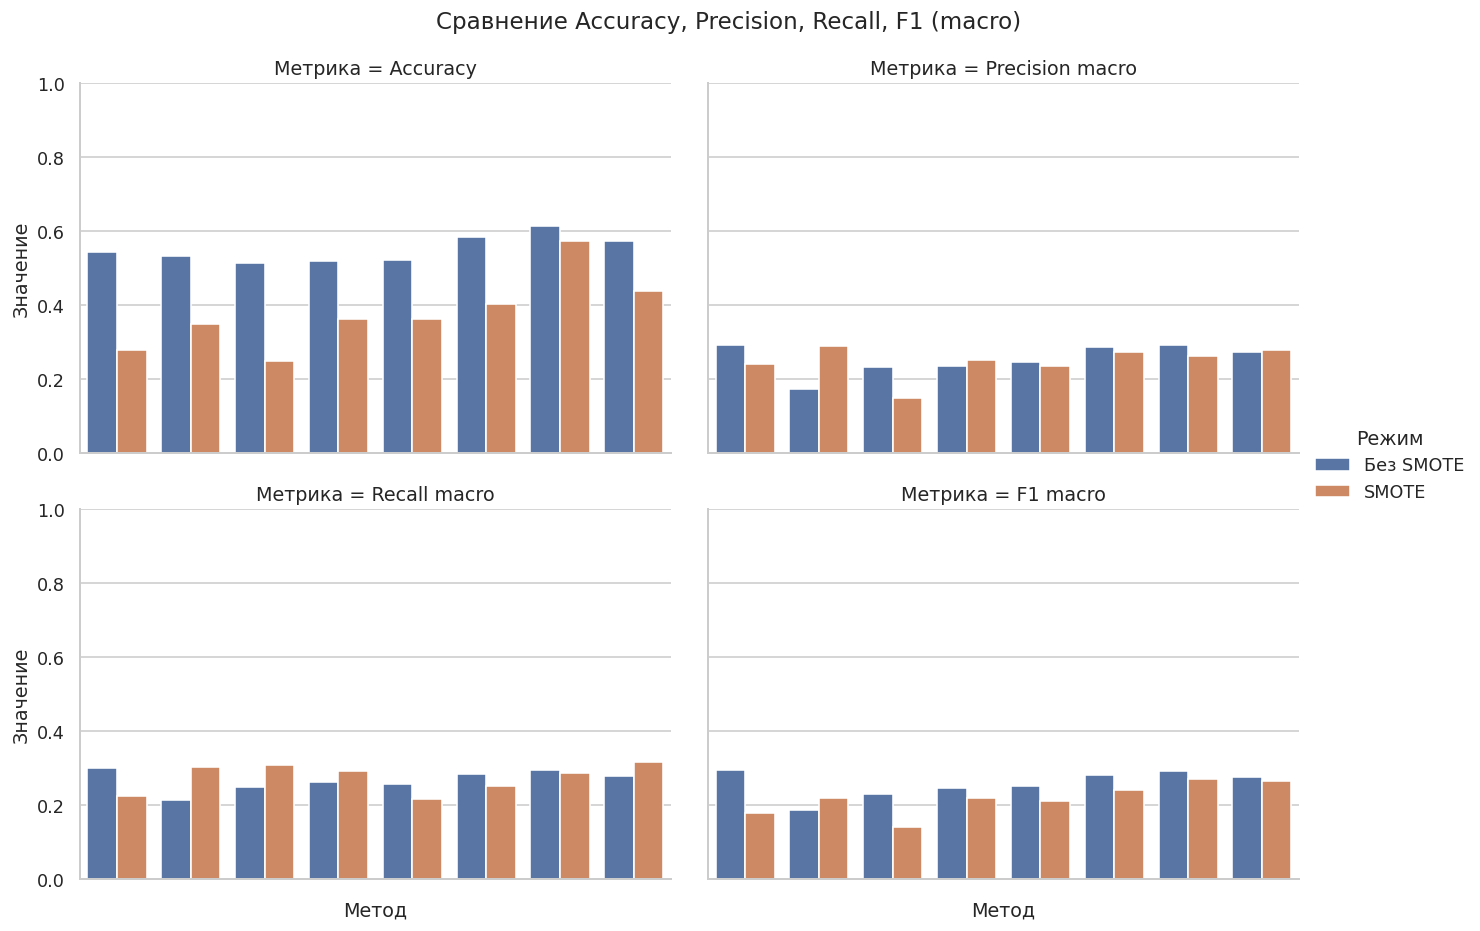

In [26]:
# Общая диаграмма метрик: все 16 вариантов, включая SMOTE.
long = test_results.melt(id_vars=["Метод", "Режим"],
                         value_vars=["Accuracy", "Precision macro", "Recall macro", "F1 macro"],
                         var_name="Метрика", value_name="Значение")
g = sns.catplot(data=long, kind="bar", x="Метод", y="Значение", hue="Режим",
                col="Метрика", col_wrap=2, height=4, aspect=1.45, sharey=True)
g.set_xticklabels(rotation=35)
g.set(ylim=(0, 1))
g.fig.suptitle("Сравнение Accuracy, Precision, Recall, F1 (macro)", y=1.03)
plt.show()

**Итог сравнения классических методов.** Графики показывают компромисс между метриками и влияние SMOTE. Сравнивать модели корректно только на одинаковых отложенных данных. Лучшая конфигурация для практической задачи зависит от того, что важнее: общая Accuracy или распознавание редких классов.

## 6. Влияние гиперпараметров

Как в принятой работе-образце, построим таблицы и графики параметров. В отличие от простого перебора на Test, будем использовать **`cv_results_` из GridSearchCV**, поскольку тестовая выборка должна оставаться независимой.

GaussianNB: {'model__var_smoothing': [1e-09, 1e-07, 1e-05]}
MultinomialNB: {'model__alpha': [0.1, 1.0, 5.0]}
ComplementNB: {'model__alpha': [0.1, 1.0, 5.0]}
BernoulliNB: {'model__alpha': [0.1, 1.0], 'model__binarize': [0.3, 0.6]}
Decision Tree: {'model__criterion': ['gini', 'entropy'], 'model__max_depth': [4, 8], 'model__min_samples_leaf': [2, 6]}
LDA: {'model__shrinkage': [None, 'auto', 0.2]}
SVM: {'estimator__model__C': [1.0, 5.0], 'estimator__model__gamma': ['scale', 0.1]}
kNN: {'model__n_neighbors': [5, 11], 'model__weights': ['uniform', 'distance']}


,param_model__criterion,param_model__max_depth,param_model__min_samples_leaf,mean_train_score,mean_test_score
6,entropy,8,2,0.7055,0.2760
2,gini,8,2,0.6612,0.2731
4,entropy,4,2,0.3249,0.2547
5,entropy,4,6,0.3199,0.2534
3,gini,8,6,0.4629,0.2498
0,gini,4,2,0.3051,0.2488
7,entropy,8,6,0.4755,0.2465
1,gini,4,6,0.2978,0.2430


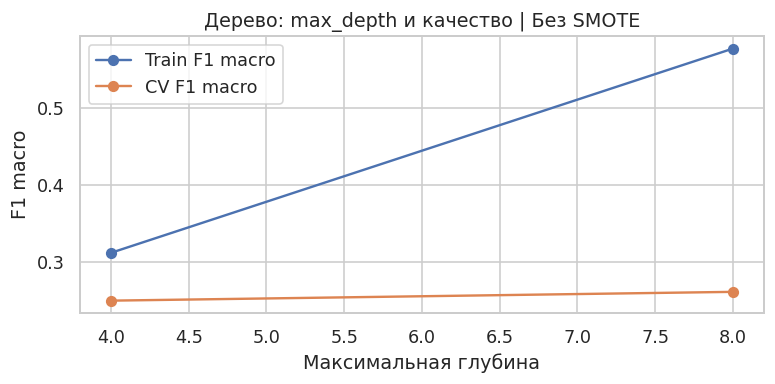

,param_model__criterion,param_model__max_depth,param_model__min_samples_leaf,mean_train_score,mean_test_score
3,gini,8,6,0.5501,0.2714
2,gini,8,2,0.6141,0.2656
6,entropy,8,2,0.6411,0.2578
4,entropy,4,2,0.3031,0.2420
5,entropy,4,6,0.3031,0.2401
7,entropy,8,6,0.5711,0.2389
0,gini,4,2,0.2967,0.2046
1,gini,4,6,0.2962,0.2024


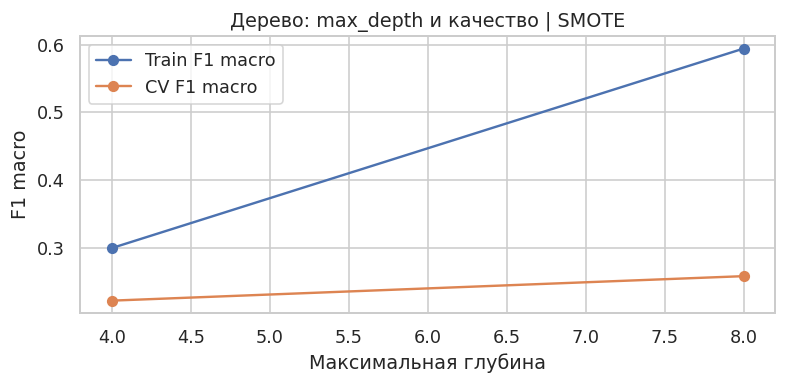

In [27]:
# Сетки параметров всех восьми классификаторов.
for name, cfg in models_config.items():
    print(name + ":", cfg["grid"])

# Подробный пример: глубина дерева, F1 macro на обучении и валидации.
for mode in ("Без SMOTE", "SMOTE"):
    gs_tree = searches[("Decision Tree", mode)]
    grid = pd.DataFrame(gs_tree.cv_results_)
    cols = ["param_model__criterion", "param_model__max_depth",
            "param_model__min_samples_leaf", "mean_train_score", "mean_test_score"]
    display(grid[cols].sort_values("mean_test_score", ascending=False).head(8).round(4))
    means = grid.groupby("param_model__max_depth", as_index=False)[["mean_train_score", "mean_test_score"]].mean()
    plt.figure(figsize=(7, 3.5))
    plt.plot(means["param_model__max_depth"], means["mean_train_score"], "o-", label="Train F1 macro")
    plt.plot(means["param_model__max_depth"], means["mean_test_score"], "o-", label="CV F1 macro")
    plt.title("Дерево: max_depth и качество | " + mode)
    plt.xlabel("Максимальная глубина"); plt.ylabel("F1 macro"); plt.legend()
    plt.tight_layout();plt.show()

**Интерпретация.** Повышение `max_depth` обычно позволяет лучше подстроиться под обучающие данные, но не обязано улучшать качество на новых объектах. Значительный рост Train F1 при неизменном или падающем CV F1 указывает на переобучение. Аналогично по `cv_results_` можно исследовать `var_smoothing`, `alpha`, `C`, `gamma`, `n_neighbors` и `weights`.

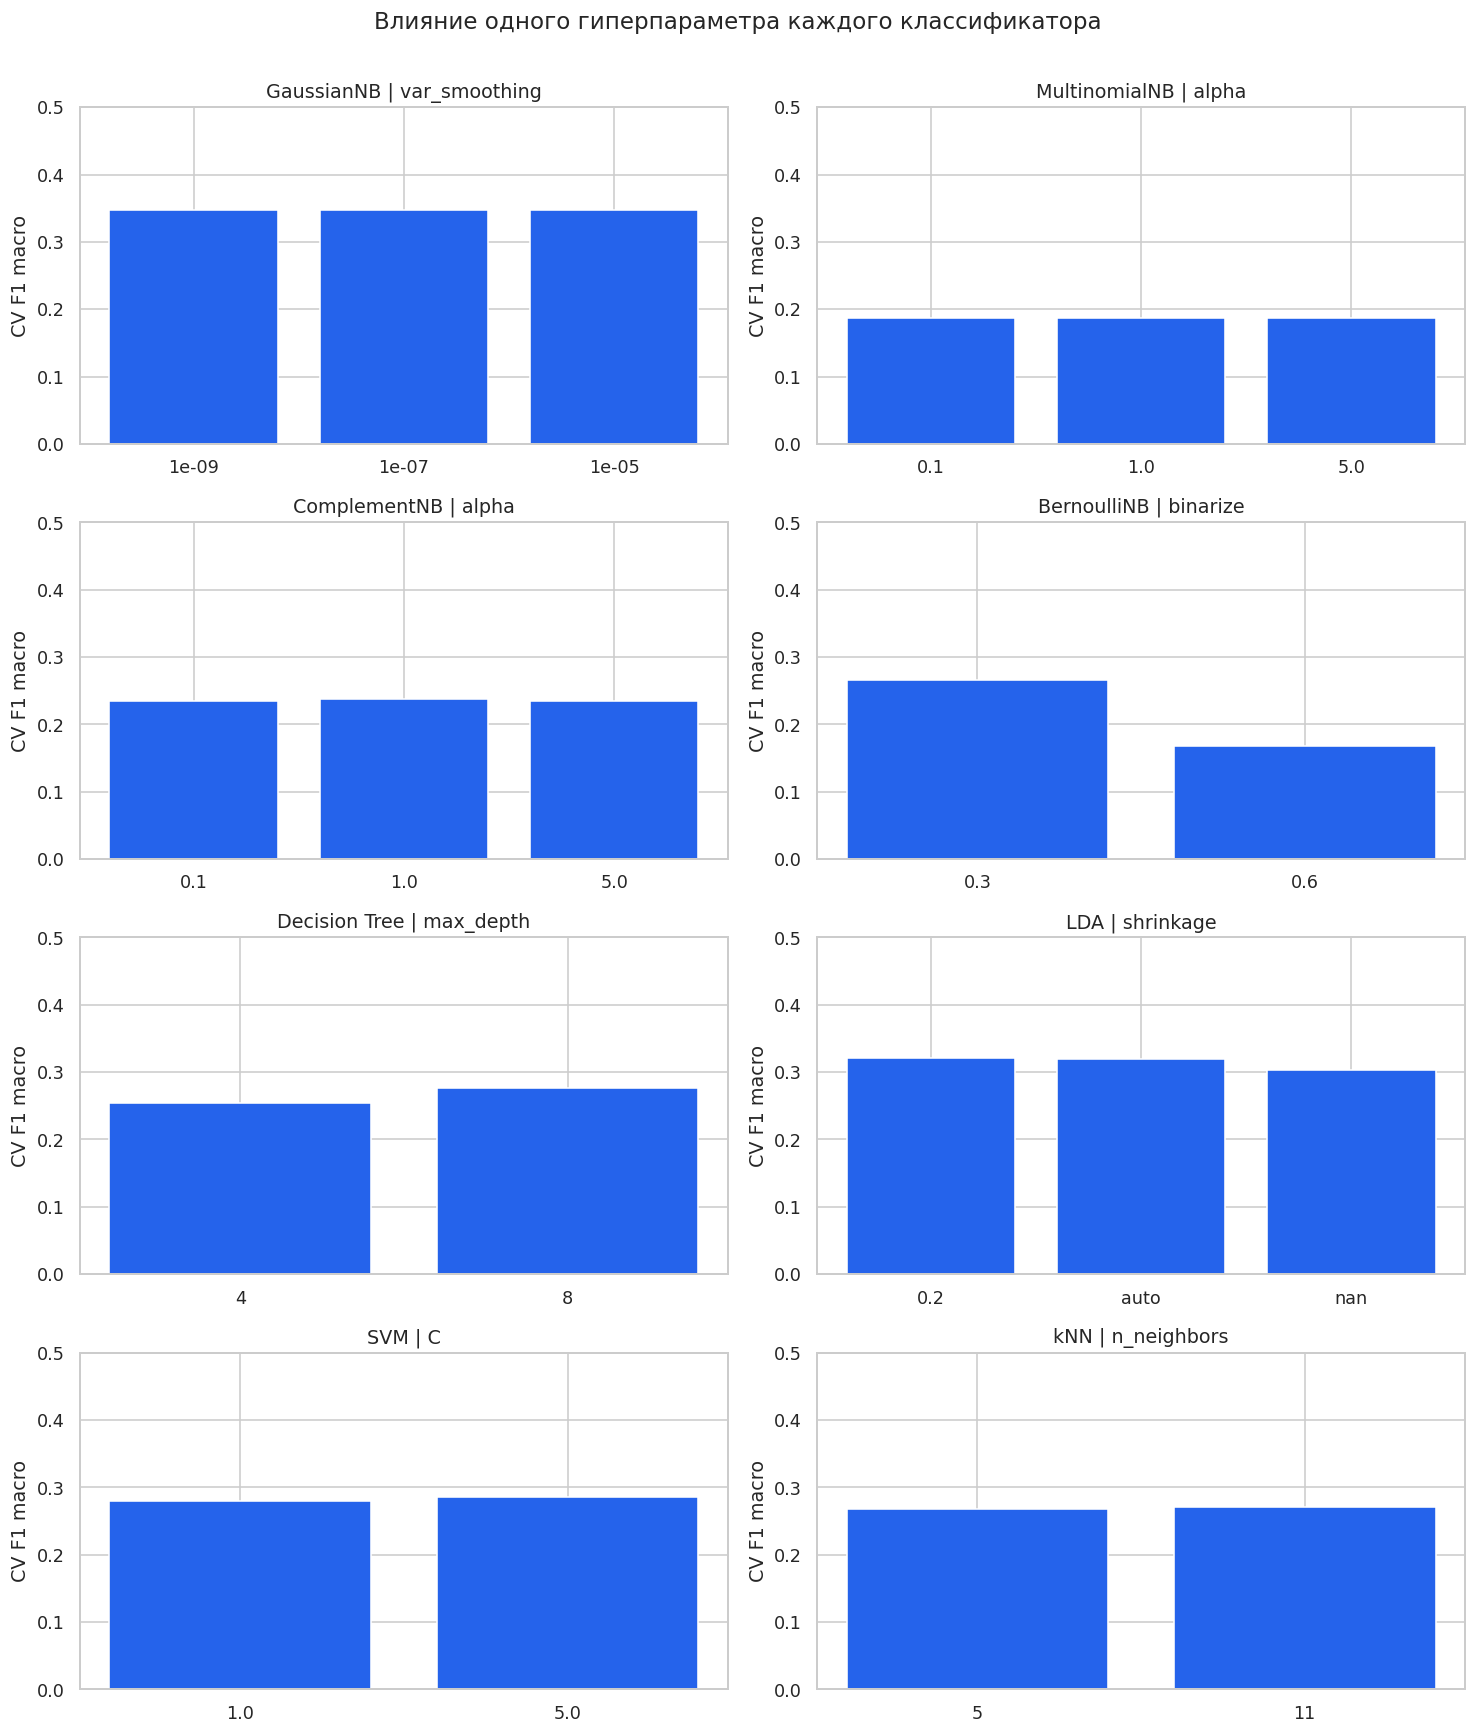

In [28]:
# Один параметр каждого семейства: максимальный CV F1 по его значениям.
focus_params = {
    "GaussianNB": "model__var_smoothing", "MultinomialNB": "model__alpha",
    "ComplementNB": "model__alpha", "BernoulliNB": "model__binarize",
    "Decision Tree": "model__max_depth", "LDA": "model__shrinkage",
    "SVM": "estimator__model__C", "kNN": "model__n_neighbors"
}
fig, axes = plt.subplots(4, 2, figsize=(13, 15))
for ax, (name, param) in zip(axes.flat, focus_params.items()):
    grid = pd.DataFrame(searches[(name, "Без SMOTE")].cv_results_)
    by_param = grid.groupby("param_" + param, dropna=False)["mean_test_score"].max()
    ax.bar([str(v) for v in by_param.index], by_param.values, color="#2563eb")
    ax.set_title(name + " | " + param.split("__")[-1])
    ax.set_ylabel("CV F1 macro")
    ax.set_ylim(0, max(0.5, float(by_param.max())*1.25))
plt.suptitle("Влияние одного гиперпараметра каждого классификатора", y=1.004)
plt.tight_layout();plt.show()

**Вывод.** Подбор гиперпараметров важен для всех пяти семейств классификаторов, но выигрыш зависит от модели и данных. Показанное качество вычислено на кросс-валидации; тест не используется как руководство при переборе.

## 7. Нейронная сеть TensorFlow/Keras

**В этом разделе после обучения КАЖДОЙ сети выводятся два графика:** функции потерь и точности на обучающей и валидационной выборках. Ниже есть и общее сравнение экспериментов. Графики появляются при выполнении ячеек раздела 7, а после `Ctrl+S` сохраняются в `.ipynb`.

Как в работе одногруппника, построим многослойный перцептрон (**MLP**) с Dense-слоями и изучим влияние параметров. Но у нас **шесть классов**, поэтому выходной слой содержит **6 нейронов с softmax**, а функция потерь — `sparse_categorical_crossentropy` (не бинарная `binary_crossentropy`).

Сравним четыре эксперимента: две архитектуры, Dropout и наличие SMOTE. Валидация выделяется только из Train; масштабирование и SMOTE не обучаются на Test и Validation.

**Замечание об окружении:** TensorFlow 2.21 в обычной Windows использует CPU; отсутствие CUDA-GPU здесь ожидаемо, а не ошибка. Временные предупреждения о повторной трассировке исключаются прямым вызовом `model(X, training=False)` вместо многократного `predict()` при переборе архитектур.


In [ ]:
import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("CPU/GPU:", tf.config.list_physical_devices())
tf.keras.utils.set_random_seed(SEED)

from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
label_encoder.fit(class_labels)

# Стратифицированная валидация из Train (не из Test).
X_nn_train, X_nn_val, y_nn_train, y_nn_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=SEED, stratify=y_train
)

nn_imputer = SimpleImputer(strategy="median")
X_nn_train_imp = nn_imputer.fit_transform(X_nn_train)
X_nn_val_imp = nn_imputer.transform(X_nn_val)
X_nn_test_imp = nn_imputer.transform(X_test)

nn_scaler = StandardScaler()
X_nn_train_std = nn_scaler.fit_transform(X_nn_train_imp).astype("float32")
X_nn_val_std = nn_scaler.transform(X_nn_val_imp).astype("float32")
X_nn_test_std = nn_scaler.transform(X_nn_test_imp).astype("float32")

y_nn_train_idx = label_encoder.transform(y_nn_train)
y_nn_val_idx = label_encoder.transform(y_nn_val)
y_nn_test_idx = label_encoder.transform(y_test)
print("MLP train/val/test:", X_nn_train_std.shape, X_nn_val_std.shape, X_nn_test_std.shape)
print("Кодирование:", dict(enumerate(label_encoder.classes_)))

**Пояснение.** `LabelEncoder` преобразует исходные классы 3…8 в индексы 0…5. Только на `X_nn_train` обучаются заполнение пропусков и стандартизатор. Подбор архитектуры осуществляется по Validation, а Test будет использован один раз для выбранной нейросети.

In [ ]:
# Несколько управляемых параметров, по аналогии с работой-образцом.
NN_EXPERIMENTS = [
    {"name": "MLP_16_noSMOTE", "hidden": (16,), "dropout": 0.0, "lr": 0.001, "batch_size": 32, "smote": False},
    {"name": "MLP_32_16_noSMOTE", "hidden": (32, 16), "dropout": 0.0, "lr": 0.001, "batch_size": 32, "smote": False},
    {"name": "MLP_32_16_SMOTE", "hidden": (32, 16), "dropout": 0.0, "lr": 0.001, "batch_size": 32, "smote": True},
    {"name": "MLP_64_32_SMOTE_Dropout", "hidden": (64, 32), "dropout": 0.25, "lr": 0.0005, "batch_size": 32, "smote": True},
]

def create_mlp(hidden=(32,16), dropout=0.0, lr=0.001):
    model = tf.keras.Sequential(name="Wine_Quality_MLP")
    model.add(tf.keras.Input(shape=(X_nn_train_std.shape[1],)))
    for units in hidden:
        model.add(tf.keras.layers.Dense(units, activation="relu"))
        if dropout > 0:
            model.add(tf.keras.layers.Dropout(dropout))
    model.add(tf.keras.layers.Dense(len(class_labels), activation="softmax"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

model_demo = create_mlp()
model_demo.summary()
display(pd.DataFrame(NN_EXPERIMENTS))

def show_training_curves(history, experiment_name):
    """Кривые loss/accuracy для Train и Validation; работает с Keras History или dict."""
    h = history.history if hasattr(history, "history") else history
    required = ("loss", "val_loss", "accuracy", "val_accuracy")
    absent = [key for key in required if key not in h]
    if absent:
        raise ValueError(f"Нет метрик в History: {absent}")

    epochs = np.arange(1, len(h["loss"]) + 1)
    best_epoch = int(np.argmin(h["val_loss"])) + 1
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.1))
    for ax, key, val_key, title, label in (
        (axes[0], "loss", "val_loss", "Функция потерь", "Loss"),
        (axes[1], "accuracy", "val_accuracy", "Доля правильных ответов", "Accuracy"),
    ):
        ax.plot(epochs, h[key], color="#2563eb", lw=2, label="Обучение (Train)")
        ax.plot(epochs, h[val_key], color="#ea580c", lw=2, label="Валидация (Validation)")
        ax.axvline(best_epoch, color="#64748b", ls=":", lw=1.5,
                   label=f"Мин. val_loss — эпоха {best_epoch}")
        ax.set(xlabel="Эпоха", ylabel=label, title=title)
        ax.grid(alpha=.22)
        ax.legend(loc="best", fontsize=8)
    fig.suptitle(f"Обучение нейросети: {experiment_name}", fontsize=13, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()
    print(f"Графики: {len(epochs)} эпох. Минимум val_loss: "
          f"{h['val_loss'][best_epoch-1]:.4f} (эпоха {best_epoch}). "
          f"Финальная train accuracy: {h['accuracy'][-1]:.4f}, "
          f"val accuracy: {h['val_accuracy'][-1]:.4f}.")


**Архитектура.** Вход содержит 11 чисел; скрытые Dense-слои с ReLU изучают нелинейные зависимости; выходной softmax возвращает 6 вероятностей, сумма которых равна 1. `Dropout` случайно отключает часть активаций при обучении для регуляризации. `Adam` обновляет веса с заданной скоростью `learning_rate`.

**Следующий блок обучает четыре конфигурации:** сразу после каждого сообщения «Завершено эпох» будут показаны две кривые Train/Validation и пояснение числа эпох и лучшего `val_loss`.


In [ ]:
# TensorBoard callback записывает РЕАЛЬНЫЕ события эпох в каталог рядом с notebook.
# Никакого фиксированного порта и старой встроенной веб-панели.
LOG_ROOT = Path.cwd() / "tensorboard_logs" / "wine_lab2"
LOG_ROOT.mkdir(parents=True, exist_ok=True)
run_id = datetime.now().strftime("%Y%m%d_%H%M%S")

nn_models, nn_histories, nn_validation_probs, nn_rows = {}, {}, {}, []
for cfg in NN_EXPERIMENTS:
    # Не вызываем clear_session(): модели остаются в nn_models для сравнения.
    # Этот вызов в некоторых сборках Keras порождает deprecated reset_default_graph.
    tf.keras.utils.set_random_seed(SEED)
    model = create_mlp(cfg["hidden"], cfg["dropout"], cfg["lr"])
    x_fit, y_fit = X_nn_train_std, y_nn_train_idx
    if cfg["smote"]:
        x_fit, y_fit = SMOTE(random_state=SEED, k_neighbors=3).fit_resample(x_fit, y_fit)
        x_fit = np.asarray(x_fit, dtype="float32")
    log_dir = LOG_ROOT / f"{run_id}_{cfg['name']}"
    callbacks = [
        tf.keras.callbacks.TensorBoard(log_dir=str(log_dir), histogram_freq=0, update_freq="epoch"),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    ]
    print("\nОбучение:", cfg["name"], "| Train объектов:", len(x_fit))
    history = model.fit(
        x_fit, y_fit,
        validation_data=(X_nn_val_std, y_nn_val_idx),
        epochs=70, batch_size=cfg["batch_size"],
        callbacks=callbacks, verbose=0,
    )
    # Прямой eager-вызов вместо model.predict(), чтобы при переборе новых моделей
    # TensorFlow не создавал отдельную predict_function и не делал retracing.
    probs = np.asarray(model(X_nn_val_std, training=False))
    pred_idx = np.argmax(probs, axis=1)
    result = {
        "Эксперимент": cfg["name"], "Эпох": len(history.history["loss"]),
        "Val accuracy": accuracy_score(y_nn_val_idx, pred_idx),
        "Val F1 macro": f1_score(y_nn_val_idx, pred_idx, labels=np.arange(len(class_labels)),
                                 average="macro", zero_division=0),
        "Min val_loss": min(history.history["val_loss"]),
        "Каталог логов": str(log_dir),
    }
    nn_models[cfg["name"]] = model
    nn_histories[cfg["name"]] = history.history
    nn_validation_probs[cfg["name"]] = probs
    nn_rows.append(result)
    print(f"Завершено эпох: {result['Эпох']} | Val F1 macro: {result['Val F1 macro']:.4f} | "
          f"лучший val_loss: {result['Min val_loss']:.4f}")

    # ВЫВОД ПОСЛЕ КАЖДОЙ МОДЕЛИ: настоящие графики ее обучения.
    # Matplotlib-рисунки сохраняются в .ipynb при Ctrl+S и видны на GitHub.
    show_training_curves(history, cfg["name"])

nn_results = pd.DataFrame(nn_rows).sort_values("Val F1 macro", ascending=False).reset_index(drop=True)
display(nn_results[["Эксперимент", "Эпох", "Val accuracy", "Val F1 macro", "Min val_loss"]].round(4))

### 7.1. Что показали четыре эксперимента

Для каждого эксперимента выше построены **два графика по эпохам**: `loss` и `accuracy`. Оранжевая линия относится к Validation, синяя — к Train. Пунктирная вертикальная линия отмечает эпоху с минимальной валидационной функцией потерь.

**Как оценивать:** снижение обеих ошибок — признак обучения; если train loss снижается, а val loss устойчиво растёт — возможное переобучение. Если обе кривые остаются высокими и почти не меняются, может наблюдаться недообучение. SMOTE следует оценивать по качеству на неизменённой валидационной выборке, а не по красоте кривых.


In [ ]:
# Сопоставление итоговых метрик четырёх нейросетей на одной Validation.
plot_nn = nn_results.sort_values("Эксперимент").copy()
positions = np.arange(len(plot_nn))
width = 0.36
fig, ax = plt.subplots(figsize=(11.5, 4.5))
ax.bar(positions-width/2, plot_nn["Val accuracy"], width=width, color="#2563eb", label="Validation Accuracy")
ax.bar(positions+width/2, plot_nn["Val F1 macro"], width=width, color="#0f766e", label="Validation F1 macro")
ax.set_xticks(positions, plot_nn["Эксперимент"], rotation=15, ha="right")
ax.set_ylim(0, 1.02)
ax.set_ylabel("Значение метрики")
ax.set_title("Сравнение конфигураций нейросети на Validation")
ax.legend()
ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()

leader = nn_results.iloc[0]
print(f"Лучшая модель по Validation F1 macro: {leader['Эксперимент']}, "
      f"F1 macro={leader['Val F1 macro']:.4f}.")

**Вывод по сравнению.** `Accuracy` отражает общую долю правильных предсказаний, а `F1 macro` придаёт одинаковую значимость всем шести классам. При дисбалансе 3 и 8 классов именно макро-F1 полезно использовать для выбора лучшей нейросети. Значения взяты из настоящих прогнозов на отдельной Validation, а не подобраны вручную.

In [ ]:
# 7.2. Общее сравнение кривых всех четырёх моделей.
assert len(nn_histories) == 4, "Сначала выполните ячейку обучения четырёх нейросетей выше."
# Графики строятся прямо из history: гарантированно видны и сохраняются в .ipynb.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, history in nn_histories.items():
    epochs_axis = np.arange(1, len(history["loss"]) + 1)
    axes[0].plot(epochs_axis, history["loss"], alpha=.7, label=f"{name}: train")
    axes[0].plot(epochs_axis, history["val_loss"], linestyle="--", label=f"{name}: val")
    axes[1].plot(epochs_axis, history["accuracy"], alpha=.7, label=f"{name}: train")
    axes[1].plot(epochs_axis, history["val_accuracy"], linestyle="--", label=f"{name}: val")
axes[0].set(xlabel="Эпоха", ylabel="Loss", title="Изменение функции потерь")
axes[1].set(xlabel="Эпоха", ylabel="Accuracy", title="Доля правильных прогнозов")
for ax in axes: ax.legend(fontsize=7); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

**Как интерпретировать графики:** снижение `train loss` означает подстройку модели к обучающим данным; для оценки обобщения особенно важен `val_loss`. Если `train loss` продолжает снижаться, а `val_loss` растёт, возможно переобучение. Если оба остаются большими и почти не улучшаются — возможно недообучение.

## 8. TensorBoard: настоящие журналы **внутри лабораторной**

TensorBoard записывает журналы через `TensorBoard` callback во время `fit`. В VS Code встроенный веб-интерфейс `%tensorboard` иногда показывает пустой iframe даже при исправных данных. Поэтому **основная визуализация ниже считывает именно файлы событий TensorBoard** (`events.out.tfevents.*`) и строит графики прямо в `.ipynb`. Это не имитация: данные читаются из настоящих логов. Живой веб-интерфейс остаётся необязательным.

In [ ]:
from tensorboard.backend.event_processing import event_accumulator

event_files = sorted(LOG_ROOT.rglob("events.out.tfevents.*"))
print("Путь к журналам:", LOG_ROOT)
print("Найдено файлов TensorBoard:", len(event_files))
assert event_files, "Файлы TensorBoard не найдены: сначала выполните обучение нейросетей в разделе 7."

def read_tb_scalars(folder):
    acc = event_accumulator.EventAccumulator(str(folder),
        size_guidance={"scalars": 0, "tensors": 0})
    acc.Reload()
    result = {}
    for key in acc.Tags().get("scalars", []):
        result[key] = [(v.step, float(v.value)) for v in acc.Scalars(key)]
    for key in acc.Tags().get("tensors", []):
        if key not in result:
            values = []
            for ev in acc.Tensors(key):
                try:
                    v = float(np.asarray(tf.make_ndarray(ev.tensor_proto)).reshape(-1)[0])
                    values.append((ev.step, v))
                except (TypeError, ValueError):
                    pass
            if values:
                result[key] = values
    return result

# Выводим реальные теги последнего запуска и рисуем train/validation scalars.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
read_count = 0
for cfg in NN_EXPERIMENTS:
    run_folder = LOG_ROOT / f"{run_id}_{cfg['name']}"
    for part, dash in [("train", "-"), ("validation", "--")]:
        folder = run_folder / part
        if not folder.exists():
            continue
        tags = read_tb_scalars(folder)
        if cfg == NN_EXPERIMENTS[0]:
            print(f"Теги первого эксперимента ({part}):", list(tags))
        for ax, metric in zip(axes, ("loss", "accuracy")):
            candidate_keys = [t for t in tags if t == "epoch_" + metric or t.endswith("/"+metric) or t == metric]
            if not candidate_keys:
                candidate_keys = [t for t in tags if t.endswith("epoch_"+metric)]
            if candidate_keys:
                xy = np.asarray(tags[candidate_keys[0]])
                ax.plot(xy[:,0], xy[:,1], linestyle=dash, label=f"{cfg['name']}: {part}")
                read_count += 1
axes[0].set(title="TensorBoard events: Loss", xlabel="Шаг/эпоха", ylabel="Loss")
axes[1].set(title="TensorBoard events: Accuracy", xlabel="Шаг/эпоха", ylabel="Accuracy")
for ax in axes: ax.legend(fontsize=7); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()
print("Серий считано из логов TensorBoard:", read_count)
if read_count == 0:
    print("Теги в этой версии TensorFlow отличаются. Графики history из предыдущей ячейки остаются доступными.")

**Вывод.** Графики построены из файлов TensorBoard, созданных при `fit`, и **сохраняются в самом `.ipynb`** после `Ctrl+S`. Они не зависят от порта `6006/6009` и от поддержки встраивания веб-страниц в VS Code. При желании можно дополнительно открыть полноценный интерактивный TensorBoard командой из терминала `python -m tensorboard.main --logdir tensorboard_logs/wine_lab2`, но для отображения результатов в лабораторной это не требуется.

## 9. Итоговая проверка лучшей нейросети на Test

Выберем архитектуру по **валидационному F1 macro** и только теперь один раз оценим её на нетронутой тестовой выборке. Сравним с лучшим классическим методом, который был выбран по CV.

In [ ]:
chosen_nn_name = nn_results.iloc[0]["Эксперимент"]
chosen_nn = nn_models[chosen_nn_name]
test_nn_probs = np.asarray(chosen_nn(X_nn_test_std, training=False))
indices_pred = np.argmax(test_nn_probs, axis=1)
pred_nn = label_encoder.inverse_transform(indices_pred)

nn_metrics = {
    "Accuracy": accuracy_score(y_test, pred_nn),
    "Precision macro": precision_score(y_test, pred_nn, average="macro", zero_division=0),
    "Recall macro": recall_score(y_test, pred_nn, average="macro", zero_division=0),
    "F1 macro": f1_score(y_test, pred_nn, average="macro", zero_division=0),
    "ROC AUC macro OvR": roc_auc_score(y_nn_test_idx, test_nn_probs,
                                     labels=np.arange(len(class_labels)),
                                     multi_class="ovr", average="macro"),
}
classic_metrics = test_results[
    (test_results["Метод"] == selected_key[0]) & (test_results["Режим"] == selected_key[1])
].iloc[0]
compare_final = pd.DataFrame([
    {"Модель": "Классическая: " + "/".join(selected_key),
     **{k: classic_metrics[k] for k in nn_metrics}},
    {"Модель": "Нейросеть: " + chosen_nn_name, **nn_metrics}
]).set_index("Модель")
display(compare_final.round(4))
print("Выбранная нейросеть:", chosen_nn_name)
print(classification_report(y_test, pred_nn, labels=class_labels, zero_division=0))
nn_confusion_matrix = plot_confusion_like_sample(
    y_test, pred_nn,
    "нейросети: " + chosen_nn_name,
)


**Вывод.** Таблица показывает качество лучшей нейросети и лучшего классического метода на **одном и том же Test**. Выбор нейросети сделан по Validation, а классической модели — по CV. Это снижает риск подгонки по тестовым данным. В реальных задачах при крайне редких классах полезны дополнительные независимые данные и повторная оценка на других разбиениях.

## 10. Общие выводы по лабораторной работе

1. Подготовлен датасет Wine Quality: целевая переменная `quality` рассматривается как **шесть категорий**, а не как непрерывная оценка регрессии.
2. Выявлен дисбаланс классов. Для его исследования применяется **SMOTE только на тренировочных данных и внутри CV**, а тестовое распределение оставлено исходным.
3. Обучены четыре варианта наивного Байеса, дерево решений, LDA, SVM и kNN; исследованы гиперпараметры с помощью `GridSearchCV` и `StratifiedKFold`.
4. Для сравнения используются Accuracy, Precision macro, Recall macro, F1 macro, ROC-AUC macro OvR и матрицы ошибок. При дисбалансе особое внимание уделяется **F1 macro**.
5. Построены нейросети TensorFlow/Keras с выходом `softmax` для шести классов, исследованы архитектуры, Dropout и SMOTE, сохранены журналы в TensorBoard.
6. Графики обучения показаны **непосредственно в ноутбуке**, в том числе через чтение журналов TensorBoard, и остаются видимыми после сохранения выполненного `.ipynb`.

**Для защиты:** откройте сначала диаграмму распределения классов, затем до/после SMOTE, сравнительную таблицу, матрицу ошибок, пример подбора гиперпараметров и в конце раздел TensorFlow/TensorBoard. Фактические лучшие численные значения представлены в таблицах, полученных выполненным кодом выше; они могут слегка отличаться при другой версии TensorFlow.

**Для GitHub загружайте только** `ЛР2_Классификация_качества_вина.ipynb` и `winequality-red.csv`. Папка `tensorboard_logs` создаётся при выполнении, но не обязательна для хранения в репозитории, поскольку журнал можно восстановить повторным запуском.